# Notebook 09 continuation — M3-RVA real training

**Purpose:** qualify and train the adapter-equipped SmolVLA on the same demonstration data and frozen training settings as M2-LE. This is a post-hoc architectural extension; it does not change the completed N00–N08 study.

**Default action when you click Run All:** rerun the short Stage A, qualify **10 runtime-warm-up + 100 timed real-data updates**, discard those diagnostic weights, then train **seed 42 for 25,000 steps from the pinned base initialization**. The expert/projection parameters used by N06 and the new adapter are optimized together. This is not adapter-only SGD and not continued fine-tuning of M2-LE.

The predeclared seed matrix is **42, 123, 2026**. The controls below launch only seed 42 by default. Selecting all three before running launches them sequentially after qualification. Completed compatible runs are reused; interrupted runs resume from the latest saved recovery. Do not choose which seeds to report based on their results.

| Stage | Data and purpose | What completion means |
|---|---|---|
| A | Synthetic integration probe, already passed in the uploaded notebook | Wiring evidence only |
| B | Real N06 training data at batch 4; full model/processors save–reload | Technical qualification and measured speed |
| C | Selected 25k training runs, offline validation, full reload | Trained checkpoints, **not** robot-performance evidence |

**Files and safety:** old checkpoints, split files, summaries and the LeRobot source are read-only. New model/recovery files go only under `experiments/m3_rva_extension/v1/`. A complete export includes an explicit M3 loader; do not use the stock loader by itself on M3. Internet downloads are disabled. No new corruption, consistency loss, architectural search, or OOD-based checkpoint selection is added here.

The new Stages B/C were syntax-checked and their isolated CPU utilities tested during preparation; **they have not been run on the real LeRobot dataset/GPU in the assistant environment**. The saved Stage A outputs are from your earlier executed upload, not fabricated B/C results. Keep the WSL machine awake and this notebook's kernel active while its worker runs. The notebook writes a project-local Python runner from a fully visible source cell so child processes can reconstruct the custom model.

**Compatibility fix (18 October 2026):** the N06 fingerprint now explicitly retains empty AST fields, avoiding the Python 3.12/3.13 `ast.dump` default-format difference. The source comparison is still enforced. The installer backs up and replaces only the exact earlier generated runner, and only before an M3 protocol/model exists. Training and evaluation settings are unchanged. Use the matching corrected N10 release.


In [1]:
# Choose before Run All. No package upgrades or changes to the original study.
RUN_M3_REAL_TRAINING = True
M3_SEEDS_TO_RUN = [42, 123, 2026]       # Use [42, 123, 2026] to queue the entire planned matrix.
# One final 25k checkpoint per selected seed; no best-OOD/model replacement search.


# 09 — Custom Robust Visual Adapter
## Stage A: source-grounded engineering preflight

**Stage A below is the previously executed engineering preflight. New Stages B/C later in this notebook qualify real data and can start final M3-RVA training.**

Source reviewed: the five SmolVLA files in the uploaded `smolvla_source_audit.txt`, from
LeRobot commit `7e241bd630a3719a56157a497ce5d08f244784f1`.
The research snapshot was on `experiment/m3-robust-visual-adapter` at
`ae20ee6dc4e66329c576e9ecc0c41ce062e9daf0`.

### What is actually tested
- Read an existing, explicitly selected local checkpoint without changing it.
- Observe connector output shapes/dtypes rather than assume their numeric dimensions.
- Add a registered visual-token adapter after the connector, before image-embedding scaling.
- Check initial identity for both the training forward path and cached action-chunk inference.
- Verify end-to-end gradients through the frozen text backbone.
- Take **two synthetic, adapter-only diagnostic updates**; these are not final training.
- Save/reconstruct the diagnostic adapter from a small sidecar, then compare fixed-input outputs.
- Hash the original checkpoint files before and after; do not alter N00–N08 or LeRobot.

### What a PASS does not mean
It does not establish improved robustness, a trained final M3 checkpoint, dataset integration,
full-batch memory feasibility, or complete final-training serialization. These remain separate gates.
Synthetic images/actions are used to test wiring, not robotic competence.

### How to run
Save this notebook under `notebooks/`, select **Python (vla-libero)**, restart its kernel,
and run all cells in order. Keep other GPU workloads stopped. Internet downloads are disabled;
a missing cached dependency should stop the run, not trigger an upgrade.
The default probe uses batch size 1. Inspect its measured memory before designing a batch-4 run.

All outputs are written to a new timestamped folder under
`results/metrics/m3_design_audit/runtime/`. Existing experiment checkpoints and registries are read only.

## 1. Environment, source pin, and audit recording

This is a local-source audit, not a package upgrade. A changed LeRobot commit or dirty tracked
LeRobot files blocks the probe so we do not accidentally test a different implementation.
The final summary distinguishes **engineering status** from **scientific status**.

In [2]:
import os
# Set before importing Hugging Face libraries in this fresh kernel.
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"

from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
import gc
import hashlib
import json
import subprocess
import sys
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

EXPECTED_LEROBOT_SHA = "7e241bd630a3719a56157a497ce5d08f244784f1"
DEVICE = "cuda"
PROBE_BATCH_SIZE = 1
ADAPTER_RANK = 64                # Engineering candidate, not a tuned scientific choice.
INITIAL_RESIDUAL_SCALE = 0.1
DIAGNOSTIC_STEPS = 2             # Only the adapter will be updated.
DIAGNOSTIC_LR = 0.01             # Probe setting; NOT the 25k training learning rate.
AUDIT_SEED = 1709
MODEL_VARIANT_FOR_AUDIT = "M2-LE"
MODEL_SEED_FOR_AUDIT = 42
CHECKPOINT_OVERRIDE = None       # Optional absolute/local path, only for a known checkpoint.


def find_root():
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "notebooks").is_dir() and (path / "configs").is_dir():
            return path
    raise RuntimeError("Open this notebook inside the existing research repository.")


def git(repo, *args):
    return subprocess.check_output(["git", "-C", str(repo), *args], text=True).strip()


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def json_value(value):
    if isinstance(value, Path): return str(value)
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, dict): return {str(k): json_value(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [json_value(v) for v in value]
    return value


def write_json(path, payload):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(json_value(payload), indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


REPO_ROOT = find_root()
LEROBOT_ROOT = Path("/home/leeming/projects/lerobot").resolve()
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN_DIR = REPO_ROOT / "results/metrics/m3_design_audit/runtime" / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
SUMMARY_PATH = RUN_DIR / "m3_preflight_summary.json"
REPORT = {
    "notebook": "09_custom_robust_visual_adapter", "stage": "ENGINEERING_PREFLIGHT",
    "run_id": RUN_ID, "engineering_status": "RUNNING", "scientific_status": "NOT_EVALUATED",
    "full_training_authorized": False, "diagnostic_data": "SYNTHETIC_ONLY",
    "probe_batch_size": PROBE_BATCH_SIZE, "checks": {}, "observations": {},
}


def check(name, passed, detail=""):
    REPORT["checks"][name] = {"pass": bool(passed), "detail": str(detail)}
    if not passed:
        REPORT["engineering_status"] = "BLOCKED"
    write_json(SUMMARY_PATH, REPORT)
    print(f"{'PASS' if passed else 'BLOCKED'} | {name}" + (f" | {detail}" if detail else ""))
    if not passed:
        raise RuntimeError(f"{name}: {detail}. Existing checkpoints have not been overwritten.")


check("CUDA available", torch.cuda.is_available(), "Use the vla-libero WSL kernel.")
check("Expected Conda environment", Path(sys.prefix).name == "vla-libero", sys.executable)
check("LeRobot source directory", LEROBOT_ROOT.is_dir(), LEROBOT_ROOT)
check("LeRobot source pin", git(LEROBOT_ROOT, "rev-parse", "HEAD") == EXPECTED_LEROBOT_SHA)
check("LeRobot tracked source clean", not git(LEROBOT_ROOT, "status", "--porcelain", "--untracked-files=no"))
versions = {}
for package in ("torch", "lerobot", "transformers", "huggingface-hub", "safetensors", "numpy"):
    try: versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError: versions[package] = "NOT_INSTALLED"
source_hashes = {
    str(path.relative_to(LEROBOT_ROOT)): sha256_file(path)
    for path in sorted((LEROBOT_ROOT / "src/lerobot/policies/smolvla").glob("*.py"))
}
REPORT["observations"]["environment"] = {
    "python": sys.version.split()[0], "python_executable": sys.executable,
    "versions": versions, "gpu": torch.cuda.get_device_name(0),
    "torch_cuda_runtime": torch.version.cuda,
    "gpu_memory_gib": torch.cuda.get_device_properties(0).total_memory / 1024**3,
    "research_head": git(REPO_ROOT, "rev-parse", "HEAD"),
    "research_status": git(REPO_ROOT, "status", "--short", "--branch"),
    "lerobot_head": EXPECTED_LEROBOT_SHA, "source_hashes": source_hashes,
}
write_json(SUMMARY_PATH, REPORT)
display(pd.DataFrame([REPORT["observations"]["environment"]]).T.rename(columns={0: "Value"}))
print("Audit outputs:", RUN_DIR)

PASS | CUDA available | Use the vla-libero WSL kernel.
PASS | Expected Conda environment | /home/leeming/miniforge3/envs/vla-libero/bin/python
PASS | LeRobot source directory | /home/leeming/projects/lerobot
PASS | LeRobot source pin
PASS | LeRobot tracked source clean


,Value
python,3.12.14
python_executable,/home/leeming/miniforge3/envs/vla-libero/bin/p...
versions,"{'torch': '2.11.0+cu128', 'lerobot': '0.6.1', ..."
gpu,NVIDIA GeForce RTX 5090
torch_cuda_runtime,12.8
gpu_memory_gib,31.815857
research_head,ae20ee6dc4e66329c576e9ecc0c41ce062e9daf0
research_status,## experiment/m3-robust-visual-adapter...origi...
lerobot_head,7e241bd630a3719a56157a497ce5d08f244784f1
source_hashes,{'src/lerobot/policies/smolvla/__init__.py': '...


Audit outputs: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_design_audit/runtime/20261019T125906_976823Z


## 2. Select an existing checkpoint and record the real experiment settings

The M2-LE seed-42 checkpoint is used **only as an engineering fixture** because it already has
this project's camera/action feature configuration. Final M3 training must start from the same
pinned base initialization as its M2-LE comparator, not receive an extra 25k steps on top of M2-LE.

We read saved settings instead of assuming class defaults equal the experiment settings.

In [3]:
REGISTRY_PATH = REPO_ROOT / "configs/experiments/definitive_final_model_registry_v1.csv"
HANDOFF_PATH = REPO_ROOT / "configs/experiments/notebook06_final_budget_handoff_v2.json"
check("Final model registry present", REGISTRY_PATH.is_file(), REGISTRY_PATH)
registry = pd.read_csv(REGISTRY_PATH)
required = {"variant", "seed", "checkpoint"}
check("Registry schema", required.issubset(registry.columns), list(registry.columns))
selected = registry[
    (registry["variant"].astype(str) == MODEL_VARIANT_FOR_AUDIT)
    & (pd.to_numeric(registry["seed"], errors="raise") == MODEL_SEED_FOR_AUDIT)
]
check("One explicit checkpoint selected", len(selected) == 1, f"{MODEL_VARIANT_FOR_AUDIT} seed {MODEL_SEED_FOR_AUDIT}")
selected_row = selected.iloc[0].to_dict()
checkpoint_text = CHECKPOINT_OVERRIDE or str(selected_row["checkpoint"])
CHECKPOINT = Path(checkpoint_text).expanduser()
if not CHECKPOINT.is_absolute(): CHECKPOINT = REPO_ROOT / CHECKPOINT
CHECKPOINT = CHECKPOINT.resolve()
check("Checkpoint stays inside project", CHECKPOINT.is_relative_to(REPO_ROOT), CHECKPOINT)
check("Local pretrained directory exists", CHECKPOINT.is_dir() and (CHECKPOINT / "config.json").is_file(), CHECKPOINT)
check("Checkpoint weights present", any(CHECKPOINT.rglob("*.safetensors")) or any(CHECKPOINT.rglob("*.bin")))
checkpoint_config = json.loads((CHECKPOINT / "config.json").read_text(encoding="utf-8"))


def checkpoint_inventory(directory):
    return [
        {"path": str(p.relative_to(directory)), "bytes": p.stat().st_size, "sha256": sha256_file(p)}
        for p in sorted(directory.rglob("*")) if p.is_file()
    ]


print("Hashing the original checkpoint files (read only)...")
INPUT_INVENTORY = checkpoint_inventory(CHECKPOINT)
CHECKPOINT_CONTENT_SHA256 = hashlib.sha256(
    json.dumps(INPUT_INVENTORY, sort_keys=True).encode("utf-8")
).hexdigest()
write_json(RUN_DIR / "input_checkpoint_inventory.json", INPUT_INVENTORY)
check("Budget handoff present", HANDOFF_PATH.is_file(), HANDOFF_PATH)
handoff = json.loads(HANDOFF_PATH.read_text(encoding="utf-8"))
check("Recorded core budget is 25k", int(handoff.get("final_training_steps", -1)) == 25000)
REPORT["observations"]["checkpoint"] = {
    "path": str(CHECKPOINT), "content_sha256": CHECKPOINT_CONTENT_SHA256,
    "variant": MODEL_VARIANT_FOR_AUDIT, "seed": MODEL_SEED_FOR_AUDIT,
    "registry_sha256": sha256_file(REGISTRY_PATH), "handoff_sha256": sha256_file(HANDOFF_PATH),
    "checkpoint_config": checkpoint_config,
    "recorded_optimizer": handoff.get("optimizer"), "recorded_scheduler": handoff.get("scheduler"),
    "recorded_training_scope": handoff.get("training_scope"),
    "recorded_base_revision": handoff.get("base_model_revision"),
    "recorded_dataset_revision": handoff.get("dataset_revision"),
    "recorded_split_file": handoff.get("split_file"),
}
write_json(SUMMARY_PATH, REPORT)
display(pd.DataFrame([{
    "fixture": f"{MODEL_VARIANT_FOR_AUDIT} seed {MODEL_SEED_FOR_AUDIT}",
    "checkpoint": str(CHECKPOINT),
    "class_flags_in_saved_config": {k: checkpoint_config.get(k) for k in
        ("freeze_vision_encoder", "train_expert_only", "train_state_proj", "load_vlm_weights")},
    "optimizer_from_handoff": handoff.get("optimizer"),
    "scheduler_from_handoff": handoff.get("scheduler"),
}]).T.rename(columns={0: "Value"}))

PASS | Final model registry present | /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/definitive_final_model_registry_v1.csv
PASS | Registry schema | ['variant', 'seed', 'role', 'training_steps', 'language_levels', 'environment_augmentation', 'checkpoint', 'checkpoint_signature', 'validation_loss', 'source_notebook']
PASS | One explicit checkpoint selected | M2-LE seed 42
PASS | Checkpoint stays inside project | /home/leeming/projects/deep-learning-vla-robustness/experiments/validated_final_retraining/m2le_seed42_25000/model
PASS | Local pretrained directory exists | /home/leeming/projects/deep-learning-vla-robustness/experiments/validated_final_retraining/m2le_seed42_25000/model
PASS | Checkpoint weights present
Hashing the original checkpoint files (read only)...
PASS | Budget handoff present | /home/leeming/projects/deep-learning-vla-robustness/configs/experiments/notebook06_final_budget_handoff_v2.json
PASS | Recorded core budget is 25k


,Value
fixture,M2-LE seed 42
checkpoint,/home/leeming/projects/deep-learning-vla-robus...
class_flags_in_saved_config,"{'freeze_vision_encoder': True, 'train_expert_..."
optimizer_from_handoff,"{'learning_rate': 0.0001, 'weight_decay': 0.01..."
scheduler_from_handoff,"{'warmup_steps': 2500, 'cosine_decay_end_step'..."


## 3. Candidate design: identity-initialized visual-token residual adapter

For connector output \(z\in\mathbb{R}^{B\times N\times D}\), propose

\[
f(z)=z+\alpha\,W_{up}\,\mathrm{GELU}(W_{down}\,\mathrm{LN}(z)).
\]

Bias terms are included. `D` is read from the live model; `N` is observed at runtime.
The candidate bottleneck is 64, shared across camera streams and tokens. This first candidate
has no spatial convolution, token mixing, new input modality, or dropout.

Initialize the up-projection to zero and the residual scale to a **nonzero** 0.1. This preserves
the original model output initially. On the first backward pass, earlier adapter gradients can
legitimately be zero; the up-projection must receive signal. After an update, the down-projection
must also receive signal. Setting both the scale and up-projection to zero would block learning.

This module is a proposed implementation of established residual-adapter ideas, not a claim
that adapters were invented for this assignment.

In [4]:
class RobustVisualAdapter(nn.Module):
    """Token-wise, shape-preserving adapter. Implementation candidate for the M3 audit."""

    def __init__(self, hidden_size: int, rank: int = 64, initial_scale: float = 0.1):
        super().__init__()
        if hidden_size <= 0 or not 0 < rank <= hidden_size:
            raise ValueError("Require 0 < rank <= hidden_size.")
        if not np.isfinite(initial_scale) or initial_scale == 0:
            raise ValueError("Use a finite nonzero scale with the zero up-projection.")
        self.hidden_size = int(hidden_size)
        self.rank = int(rank)
        self.norm = nn.LayerNorm(hidden_size)
        self.down = nn.Linear(hidden_size, rank)
        self.activation = nn.GELU()
        self.up = nn.Linear(rank, hidden_size)
        self.scale = nn.Parameter(torch.tensor(float(initial_scale)))
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)

    def forward(self, tokens: torch.Tensor) -> torch.Tensor:
        if tokens.ndim != 3 or tokens.shape[-1] != self.hidden_size:
            raise ValueError(f"Expected [B,N,{self.hidden_size}], got {tuple(tokens.shape)}")
        if not tokens.is_floating_point():
            raise TypeError("Connector tokens must be floating point.")
        if tokens.device != self.down.weight.device:
            raise RuntimeError("Adapter and connector output are on different devices.")
        # FP32 adapter parameters in this probe; restore the original connector dtype.
        x = tokens.to(self.down.weight.dtype)
        delta = self.up(self.activation(self.down(self.norm(x))))
        return (x + self.scale * delta).to(tokens.dtype)


def install_visual_adapter(policy, rank=64, initial_scale=0.1):
    """Register parameters outside the frozen VLM; use one instance-local connector hook.

    The hook is deliberately reconstructed by the explicit audit loader below.
    It is NOT saved automatically by an ordinary model state_dict.
    """
    core = policy.model
    if hasattr(core, "m3_visual_adapter") or hasattr(core, "_m3_visual_hook"):
        raise RuntimeError("An M3 adapter is already installed; do not install twice.")
    hidden_size = int(core.vlm_with_expert.config.text_config.hidden_size)
    connector = core.vlm_with_expert.get_vlm_model().connector
    device = next(core.parameters()).device
    adapter = RobustVisualAdapter(hidden_size, rank, initial_scale).to(device=device, dtype=torch.float32)
    core.add_module("m3_visual_adapter", adapter)

    def apply_adapter(module, inputs, output):
        if not isinstance(output, torch.Tensor):
            raise TypeError("Connector output is not a Tensor; insertion assumption is invalid.")
        return core.m3_visual_adapter(output)

    core._m3_visual_hook = connector.register_forward_hook(apply_adapter)
    return adapter


def remove_visual_adapter(policy):
    core = policy.model
    handle = getattr(core, "_m3_visual_hook", None)
    if handle is not None:
        handle.remove()
        delattr(core, "_m3_visual_hook")
    if hasattr(core, "m3_visual_adapter"):
        delattr(core, "m3_visual_adapter")


def grad_norm(parameter):
    if parameter.grad is None: return None
    return float(parameter.grad.detach().double().norm().cpu())


# Small CPU unit test; no original model is involved here.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(AUDIT_SEED)
    unit_adapter = RobustVisualAdapter(96, rank=16)
    unit_input = torch.randn(2, 7, 96)
    unit_target = torch.randn_like(unit_input)
    check("Adapter unit identity", torch.equal(unit_adapter(unit_input), unit_input))
    unit_opt = torch.optim.SGD(unit_adapter.parameters(), lr=0.01)
    first_up_grad = None
    second_down_grad = None
    for iteration in range(2):
        unit_opt.zero_grad(set_to_none=True)
        unit_loss = (unit_adapter(unit_input) - unit_target).square().mean()
        unit_loss.backward()
        if iteration == 0: first_up_grad = grad_norm(unit_adapter.up.weight)
        else: second_down_grad = grad_norm(unit_adapter.down.weight)
        unit_opt.step()
    check("Unit up-projection receives first-step gradient", first_up_grad is not None and first_up_grad > 0)
    check("Unit down-projection receives later gradient", second_down_grad is not None and second_down_grad > 0)
del unit_adapter, unit_opt, unit_input, unit_target, unit_loss

PASS | Adapter unit identity
PASS | Unit up-projection receives first-step gradient
PASS | Unit down-projection receives later gradient


## 4. Load the known local policy, without upgrading dependencies

This verifies the import points at the pinned source. The inherited loader is used only for the
original checkpoint. The custom adapter is installed separately after the original weights load.
Offline loading may stop if a nested backbone/tokenizer dependency is missing from the cache;
report that error rather than installing or downloading a different version.

In [5]:
import inspect
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.utils.constants import ACTION, OBS_STATE, OBS_LANGUAGE_TOKENS, OBS_LANGUAGE_ATTENTION_MASK

IMPORTED_SOURCE = Path(inspect.getfile(SmolVLAPolicy)).resolve()
check("Imports point to pinned source", IMPORTED_SOURCE.is_relative_to(LEROBOT_ROOT), IMPORTED_SOURCE)
gc.collect()
torch.cuda.empty_cache()
start = time.perf_counter()
try:
    policy = SmolVLAPolicy.from_pretrained(str(CHECKPOINT), local_files_only=True).to(DEVICE)
except Exception as exc:
    REPORT["engineering_status"] = "BLOCKED"
    REPORT["observations"]["load_error"] = f"{type(exc).__name__}: {exc}"
    write_json(SUMMARY_PATH, REPORT)
    raise
policy.eval()
check("Frozen-vision fixture", bool(policy.config.freeze_vision_encoder))
check("Expert-only fixture", bool(policy.config.train_expert_only))
check("No Aloha conversion in this probe", not bool(policy.config.adapt_to_pi_aloha))
check("No compiled model in this probe", not bool(policy.config.compile_model))
check("Cached inference enabled", bool(policy.config.use_cache))
BASE_FLAGS = {name: bool(p.requires_grad) for name, p in policy.named_parameters()}
BASE_VERSIONS = {name: p._version for name, p in policy.named_parameters()}
base_total = sum(p.numel() for p in policy.parameters())
base_trainable = sum(p.numel() for p in policy.parameters() if p.requires_grad)
REPORT["observations"]["loaded_model"] = {
    "load_seconds": time.perf_counter() - start,
    "total_parameters": base_total, "trainable_parameters": base_trainable,
    "hidden_size_from_config": int(policy.model.vlm_with_expert.config.text_config.hidden_size),
    "state_trainable": bool(policy.config.train_state_proj),
    "resize_imgs_with_padding": policy.config.resize_imgs_with_padding,
    "action_chunk_size": policy.config.chunk_size, "inference_flow_steps": policy.config.num_steps,
    "gpu_allocated_gib": torch.cuda.memory_allocated() / 1024**3,
}
write_json(SUMMARY_PATH, REPORT)
display(pd.DataFrame([REPORT["observations"]["loaded_model"]]).T.rename(columns={0: "Value"}))

/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`torch_dtype` is deprecated! Use `dtype` instead!


PASS | Imports point to pinned source | /home/leeming/projects/lerobot/src/lerobot/policies/smolvla/modeling_smolvla.py
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 903.62it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
PASS | Frozen-vision fixture
PASS | Expert-only fixture
PASS | No Aloha conversion in this probe
PASS | No compiled model in this probe
PASS | Cached inference enabled


,Value
load_seconds,3.659466
total_parameters,450046176
trainable_parameters,99880992
hidden_size_from_config,960
state_trainable,True
resize_imgs_with_padding,"(512, 512)"
action_chunk_size,50
inference_flow_steps,10
gpu_allocated_gib,0.862624


## 5. Synthetic interface batch and original-output reference

Images are generated in `[0,1]`; synthetic state/actions stand in for already-normalized data.
No dataset episodes, video decoder, simulator, or robustness-test outcomes are consumed.
Fixed action noise and flow time make the identity comparison controlled.
The final few synthetic action steps are masked as padding to exercise the loss-reduction path.

In [6]:
def make_synthetic_batch(policy):
    rng = torch.Generator(device="cpu").manual_seed(AUDIT_SEED)
    batch = {}
    for key, feature in policy.config.image_features.items():
        shape = tuple(int(v) for v in feature.shape)
        if len(shape) != 3 or shape[0] != 3:
            raise ValueError(f"Unsupported image feature for this probe: {key} {shape}")
        batch[key] = torch.rand((PROBE_BATCH_SIZE, *shape), generator=rng).to(DEVICE)
    state_dim = int(policy.config.input_features[OBS_STATE].shape[-1])
    action_dim = int(policy.config.action_feature.shape[0])
    batch[OBS_STATE] = (0.1 * torch.randn(PROBE_BATCH_SIZE, state_dim, generator=rng)).to(DEVICE)
    batch[ACTION] = (0.1 * torch.randn(PROBE_BATCH_SIZE, policy.config.chunk_size, action_dim, generator=rng)).to(DEVICE)
    batch["action_is_pad"] = torch.zeros(PROBE_BATCH_SIZE, policy.config.chunk_size, dtype=torch.bool, device=DEVICE)
    padding_tail = min(3, max(0, int(policy.config.chunk_size) - 1))
    if padding_tail:
        batch["action_is_pad"][:, -padding_tail:] = True
    instruction = "pick up the black bowl and place it on the plate\n"
    tokenizer = policy.model.vlm_with_expert.processor.tokenizer
    text = tokenizer(
        [instruction] * PROBE_BATCH_SIZE, return_tensors="pt", padding=True,
        truncation=True, max_length=policy.config.tokenizer_max_length,
    )
    batch[OBS_LANGUAGE_TOKENS] = text["input_ids"].to(DEVICE)
    batch[OBS_LANGUAGE_ATTENTION_MASK] = text["attention_mask"].to(device=DEVICE, dtype=torch.bool)
    noise = torch.randn(
        PROBE_BATCH_SIZE, policy.config.chunk_size, policy.config.max_action_dim, generator=rng
    ).to(DEVICE)
    flow_time = torch.full((PROBE_BATCH_SIZE,), 0.5, device=DEVICE)
    return batch, noise, flow_time


def loss_and_velocity(policy, batch, noise, flow_time):
    # The public forward returns loss, not signed flow velocity. Capture the exact
    # action_out_proj output for this engineering check; do not reconstruct it from MSE.
    captured = []
    def capture(module, inputs, output): captured.append(output)
    handle = policy.model.action_out_proj.register_forward_hook(capture)
    try:
        loss, stats = policy(batch, noise=noise.clone(), time=flow_time.clone())
    finally:
        handle.remove()
    if len(captured) != 1:
        raise RuntimeError(f"Expected one training velocity projection; got {len(captured)}")
    return loss, captured[0]


batch, fixed_noise, fixed_time = make_synthetic_batch(policy)
connector_observations = []
def observe_connector(module, inputs, output):
    if not isinstance(output, torch.Tensor): raise TypeError("Connector output is not a tensor.")
    connector_observations.append({
        "shape": list(output.shape), "dtype": str(output.dtype), "device": str(output.device),
        "requires_grad": bool(output.requires_grad),
    })
shape_hook = policy.model.vlm_with_expert.get_vlm_model().connector.register_forward_hook(observe_connector)
try:
    with torch.no_grad():
        reference_loss, reference_velocity = loss_and_velocity(policy, batch, fixed_noise, fixed_time)
        REFERENCE_LOSS = float(reference_loss.cpu())
        REFERENCE_VELOCITY = reference_velocity.detach().cpu().clone()
        policy.reset()
        REFERENCE_CHUNK = policy.predict_action_chunk(batch, noise=fixed_noise.clone()).detach().cpu().clone()
finally:
    shape_hook.remove()
check("Connector returned visual tokens", bool(connector_observations) and all(len(x["shape"]) == 3 for x in connector_observations))
check("Reference outputs finite", np.isfinite(REFERENCE_LOSS) and bool(torch.isfinite(REFERENCE_CHUNK).all()))
REPORT["observations"]["synthetic_interface"] = {
    "input_shapes": {key: list(value.shape) for key, value in batch.items()},
    "connector_calls": connector_observations,
    "velocity_shape": list(REFERENCE_VELOCITY.shape), "action_chunk_shape": list(REFERENCE_CHUNK.shape),
    "reference_loss": REFERENCE_LOSS,
}
write_json(SUMMARY_PATH, REPORT)
display(pd.DataFrame(connector_observations).drop_duplicates(subset=["dtype", "device"]))
print("Output action chunk:", tuple(REFERENCE_CHUNK.shape), "| Loss:", REFERENCE_LOSS)
del reference_loss, reference_velocity

PASS | Connector returned visual tokens
PASS | Reference outputs finite


,shape,dtype,device,requires_grad
0,"[1, 64, 960]",torch.bfloat16,cuda:0,False


Output action chunk: (1, 50, 7) | Loss: 1.0170187950134277


## 6. Install the adapter outside the frozen VLM

A **module-local connector hook** inserts the candidate without editing LeRobot or changing the
original connector's parameter names. Adapter parameters live at `policy.model.m3_visual_adapter`,
not beneath the frozen `vlm`. This is an explicit preflight integration mechanism. The hook
must be reinstalled by the custom loader; an ordinary `SmolVLAPolicy.from_pretrained` call alone
must never be advertised as loading an M3 bundle.

In [7]:
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(AUDIT_SEED + 1)
    adapter = install_visual_adapter(policy, ADAPTER_RANK, INITIAL_RESIDUAL_SCALE)
D = adapter.hidden_size
r = adapter.rank
adapter_parameters = sum(p.numel() for p in adapter.parameters())
expected_count = 2 * D * r + 3 * D + r + 1
check("Adapter parameter count", adapter_parameters == expected_count, adapter_parameters)
check("Adapter registered in policy state", all(
    f"model.m3_visual_adapter.{name}" in policy.state_dict() for name in adapter.state_dict()
))
check("Original trainability preserved", all(
    BASE_FLAGS[name] == bool(p.requires_grad) for name, p in policy.named_parameters() if name in BASE_FLAGS
))
check("All adapter parameters trainable", all(p.requires_grad for p in adapter.parameters()))
policy.train()
check("Adapter train mode survives frozen VLM", adapter.training and not policy.model.vlm_with_expert.vlm.training)
policy.eval()
REPORT["observations"]["adapter"] = {
    "implementation_id": "m3_rva_engineering_v1", "hidden_size": D, "rank": r,
    "initial_residual_scale": INITIAL_RESIDUAL_SCALE, "parameter_count": adapter_parameters,
    "added_percent_of_total": 100.0 * adapter_parameters / base_total,
    "location": "after connector, before sqrt(D) image-token scaling",
    "parameter_path": "model.m3_visual_adapter", "integration": "instance-local connector forward hook",
}
write_json(SUMMARY_PATH, REPORT)
display(pd.DataFrame([REPORT["observations"]["adapter"]]).T.rename(columns={0: "Value"}))

PASS | Adapter parameter count | 125825
PASS | Adapter registered in policy state
PASS | Original trainability preserved
PASS | All adapter parameters trainable
PASS | Adapter train mode survives frozen VLM


,Value
implementation_id,m3_rva_engineering_v1
hidden_size,960
rank,64
initial_residual_scale,0.1
parameter_count,125825
added_percent_of_total,0.027958
location,"after connector, before sqrt(D) image-token sc..."
parameter_path,model.m3_visual_adapter
integration,instance-local connector forward hook


## 7. Initial identity checks in both code paths

The source uses `embed_prefix` in training and inference. The adapter should initially preserve
both loss/velocity and the generated action chunk when the same input/noise is used.
This is not an accuracy test; it guards against accidentally changing the pretrained policy
before the adapter has learned anything.

In [8]:
with torch.no_grad():
    current_loss, current_velocity = loss_and_velocity(policy, batch, fixed_noise, fixed_time)
    policy.reset()
    current_chunk = policy.predict_action_chunk(batch, noise=fixed_noise.clone()).detach().cpu()
velocity_error = float((current_velocity.detach().cpu() - REFERENCE_VELOCITY).abs().max())
chunk_error = float((current_chunk - REFERENCE_CHUNK).abs().max())
check("Initial loss preserved", np.isclose(float(current_loss.cpu()), REFERENCE_LOSS, rtol=1e-5, atol=1e-6))
check("Initial flow velocity preserved", torch.allclose(current_velocity.detach().cpu(), REFERENCE_VELOCITY, rtol=1e-5, atol=1e-6), velocity_error)
check("Initial cached action chunk preserved", torch.allclose(current_chunk, REFERENCE_CHUNK, rtol=1e-5, atol=1e-6), chunk_error)
REPORT["observations"]["identity_errors"] = {"velocity_max_abs": velocity_error, "action_chunk_max_abs": chunk_error}
write_json(SUMMARY_PATH, REPORT)
del current_loss, current_velocity, current_chunk

PASS | Initial loss preserved
PASS | Initial flow velocity preserved
PASS | Initial cached action chunk preserved


## 8. End-to-end gradient and memory probe — two updates only

All originally trainable parameters retain their flags so the backward graph is representative
of the candidate, but the diagnostic optimizer contains **only adapter parameters**. Existing
expert/VLM parameters are not updated. This runs on synthetic batch size 1, not the final batch 4.

**Frozen weights are not the same as a detached computation.** The loss must backpropagate through
the frozen text-transformer operations to reach an adapter placed before them. This may increase
activation memory and runtime even though the added trainable parameter count is small.

An out-of-memory result here is a resource diagnostic, not evidence of poor model accuracy.

In [9]:
policy.train()
optimizer = torch.optim.SGD(adapter.parameters(), lr=DIAGNOSTIC_LR)
check("Diagnostic optimizer contains only adapter", {
    id(p) for group in optimizer.param_groups for p in group["params"]
} == {id(p) for p in adapter.parameters()})
initial_adapter_state = {key: value.detach().cpu().clone() for key, value in adapter.state_dict().items()}
gradient_rows = []
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()
try:
    for step in range(1, DIAGNOSTIC_STEPS + 1):
        policy.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        started = time.perf_counter()
        loss, velocity = loss_and_velocity(policy, batch, fixed_noise, fixed_time)
        check(f"Synthetic step {step} loss finite", bool(torch.isfinite(loss)))
        loss.backward()
        adapter_gradients = {name: grad_norm(p) for name, p in adapter.named_parameters()}
        check(f"Synthetic step {step} adapter gradients finite", all(
            value is not None and np.isfinite(value) for value in adapter_gradients.values()
        ))
        check(f"Synthetic step {step} frozen parameters have no gradients", all(
            p.grad is None for name, p in policy.named_parameters()
            if name in BASE_FLAGS and not BASE_FLAGS[name]
        ))
        if step == 1:
            check("End-to-end up-projection gradient", adapter_gradients["up.weight"] > 0)
        if step == 2:
            check("End-to-end down-projection gradient after first update", adapter_gradients["down.weight"] > 0)
        total_norm = torch.nn.utils.clip_grad_norm_(adapter.parameters(), 10.0, error_if_nonfinite=True)
        optimizer.step()
        torch.cuda.synchronize()
        gradient_rows.append({
            "step": step, "loss": float(loss.detach().cpu()),
            "up_grad_norm": adapter_gradients["up.weight"],
            "down_grad_norm": adapter_gradients["down.weight"],
            "scale_grad_norm": adapter_gradients["scale"],
            "seconds": time.perf_counter() - started,
            "peak_allocated_gib": torch.cuda.max_memory_allocated() / 1024**3,
            "peak_reserved_gib": torch.cuda.max_memory_reserved() / 1024**3,
        })
        del loss, velocity
except Exception as exc:
    REPORT["engineering_status"] = "BLOCKED"
    REPORT["observations"]["gradient_probe_error"] = f"{type(exc).__name__}: {exc}"
    write_json(SUMMARY_PATH, REPORT)
    policy.zero_grad(set_to_none=True)
    raise

check("Adapter actually updated", any(
    not torch.equal(value.detach().cpu(), initial_adapter_state[key]) for key, value in adapter.state_dict().items()
))
check("Inherited parameter versions unchanged", all(
    p._version == BASE_VERSIONS[name] for name, p in policy.named_parameters() if name in BASE_VERSIONS
))
policy.zero_grad(set_to_none=True)
policy.eval()
gradient_df = pd.DataFrame(gradient_rows)
gradient_df.to_csv(RUN_DIR / "synthetic_gradient_and_memory_probe.csv", index=False)
REPORT["observations"]["gradient_probe"] = gradient_rows
REPORT["observations"]["synthetic_adapter_updates"] = DIAGNOSTIC_STEPS
write_json(SUMMARY_PATH, REPORT)
display(gradient_df)
print("These synthetic adapter updates are NOT a final M3 training run.")

PASS | Diagnostic optimizer contains only adapter
PASS | Synthetic step 1 loss finite
PASS | Synthetic step 1 adapter gradients finite
PASS | Synthetic step 1 frozen parameters have no gradients
PASS | End-to-end up-projection gradient
PASS | Synthetic step 2 loss finite
PASS | Synthetic step 2 adapter gradients finite
PASS | Synthetic step 2 frozen parameters have no gradients
PASS | End-to-end down-projection gradient after first update
PASS | Adapter actually updated
PASS | Inherited parameter versions unchanged


,step,loss,up_grad_norm,down_grad_norm,scale_grad_norm,seconds,peak_allocated_gib,peak_reserved_gib
0,1,1.017019,0.009236,0.000000,0.000000,0.472765,1.090972,1.216797
1,2,1.017019,0.009236,0.000009,0.000011,0.060332,1.090972,1.216797


These synthetic adapter updates are NOT a final M3 training run.


## 9. Save a small diagnostic adapter sidecar

The bundle deliberately references the **unchanged original checkpoint** plus adapter weights.
It is valid only because this diagnostic did not update inherited parameters. A final M3 run
will also update its expert/state components and therefore needs a complete trained-policy bundle,
not just this sidecar. Do not put this diagnostic into any final model registry.

In [10]:
from safetensors.torch import save_file, load_file

with torch.no_grad():
    post_loss, post_velocity = loss_and_velocity(policy, batch, fixed_noise, fixed_time)
    POST_LOSS = float(post_loss.cpu())
    POST_VELOCITY = post_velocity.detach().cpu().clone()
    policy.reset()
    POST_CHUNK = policy.predict_action_chunk(batch, noise=fixed_noise.clone()).detach().cpu().clone()

BUNDLE_DIR = RUN_DIR / "synthetic_adapter_probe"
BUNDLE_DIR.mkdir(parents=True, exist_ok=False)
ADAPTER_WEIGHTS = BUNDLE_DIR / "adapter.safetensors"
save_file({key: value.detach().cpu().contiguous() for key, value in adapter.state_dict().items()}, str(ADAPTER_WEIGHTS))
manifest = {
    "kind": "SYNTHETIC_AUDIT_ONLY_DO_NOT_USE_FOR_RESULTS", "implementation_id": "m3_rva_engineering_v1",
    "base_checkpoint": str(CHECKPOINT), "base_content_sha256": CHECKPOINT_CONTENT_SHA256,
    "adapter_weights": ADAPTER_WEIGHTS.name, "adapter_weights_sha256": sha256_file(ADAPTER_WEIGHTS),
    "hidden_size": D, "rank": r, "initial_scale": INITIAL_RESIDUAL_SCALE,
    "lerobot_sha": EXPECTED_LEROBOT_SHA, "synthetic_adapter_updates": DIAGNOSTIC_STEPS,
    "inherited_parameters_updated": False,
    "reconstruction": "load base -> install_visual_adapter -> strict adapter state load",
}
write_json(BUNDLE_DIR / "adapter_manifest.json", manifest)
check("Adapter sidecar written", ADAPTER_WEIGHTS.is_file() and ADAPTER_WEIGHTS.stat().st_size > 0)

# Release the first full policy before constructing a second one.
del post_loss, post_velocity, optimizer
remove_visual_adapter(policy)
del adapter, policy
gc.collect()
torch.cuda.empty_cache()
print("Released the first model. Reconstructing a new policy instance next.")

PASS | Adapter sidecar written
Released the first model. Reconstructing a new policy instance next.


## 10. Explicit reconstruction and output comparison

This checks reconstruction in a new full policy instance, not just restoring weights into the
same adapter. A production evaluation loader must execute the same installation logic; loading
an adapter bundle as an ordinary SmolVLA directory would omit the custom mechanism.

In [11]:
def load_synthetic_probe(bundle_dir):
    manifest = json.loads((bundle_dir / "adapter_manifest.json").read_text(encoding="utf-8"))
    if manifest["kind"] != "SYNTHETIC_AUDIT_ONLY_DO_NOT_USE_FOR_RESULTS":
        raise ValueError("Wrong bundle type.")
    if manifest["lerobot_sha"] != EXPECTED_LEROBOT_SHA:
        raise ValueError("Source pin mismatch.")
    weights = bundle_dir / manifest["adapter_weights"]
    if sha256_file(weights) != manifest["adapter_weights_sha256"]:
        raise ValueError("Adapter weight hash mismatch.")
    restored = SmolVLAPolicy.from_pretrained(manifest["base_checkpoint"], local_files_only=True).to(DEVICE)
    restored_adapter = install_visual_adapter(restored, manifest["rank"], manifest["initial_scale"])
    if restored_adapter.hidden_size != manifest["hidden_size"]:
        raise ValueError("Hidden dimension mismatch.")
    restored_adapter.load_state_dict(load_file(str(weights), device="cpu"), strict=True)
    restored.eval()
    return restored


policy = load_synthetic_probe(BUNDLE_DIR)
with torch.no_grad():
    reload_loss, reload_velocity = loss_and_velocity(policy, batch, fixed_noise, fixed_time)
    policy.reset()
    reload_chunk = policy.predict_action_chunk(batch, noise=fixed_noise.clone()).detach().cpu()
reload_velocity_error = float((reload_velocity.detach().cpu() - POST_VELOCITY).abs().max())
reload_chunk_error = float((reload_chunk - POST_CHUNK).abs().max())
check("Reconstructed probe loss matches", np.isclose(float(reload_loss.cpu()), POST_LOSS, rtol=1e-5, atol=1e-6))
check("Reconstructed flow velocity matches", torch.allclose(reload_velocity.detach().cpu(), POST_VELOCITY, rtol=1e-5, atol=1e-6), reload_velocity_error)
check("Reconstructed cached action chunk matches", torch.allclose(reload_chunk, POST_CHUNK, rtol=1e-5, atol=1e-6), reload_chunk_error)
REPORT["observations"]["reconstruction_errors"] = {"velocity_max_abs": reload_velocity_error, "action_chunk_max_abs": reload_chunk_error}
write_json(SUMMARY_PATH, REPORT)
del reload_loss, reload_velocity, reload_chunk
remove_visual_adapter(policy)
del policy, batch, fixed_noise, fixed_time
gc.collect()
torch.cuda.empty_cache()

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1937.92it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
PASS | Reconstructed probe loss matches
PASS | Reconstructed flow velocity matches
PASS | Reconstructed cached action chunk matches


## 11. Final integrity checks and honest status

A PASS finishes the **synthetic engineering preflight**. Full 25k training is still blocked until
real-data preprocessing/augmentation, full-batch memory, initialization, and full checkpoint
packaging are checked. A positive synthetic gradient is not evidence of an OOD improvement.

In [12]:
print("Verifying original checkpoint and source files are unchanged...")
AFTER_INVENTORY = checkpoint_inventory(CHECKPOINT)
check("Original checkpoint bytes unchanged", AFTER_INVENTORY == INPUT_INVENTORY)
check("LeRobot source bytes unchanged", all(
    sha256_file(LEROBOT_ROOT / relative) == digest for relative, digest in source_hashes.items()
))
check("LeRobot revision unchanged", git(LEROBOT_ROOT, "rev-parse", "HEAD") == EXPECTED_LEROBOT_SHA)
check("Model registry unchanged", sha256_file(REGISTRY_PATH) == REPORT["observations"]["checkpoint"]["registry_sha256"])
check("Original handoff unchanged", sha256_file(HANDOFF_PATH) == REPORT["observations"]["checkpoint"]["handoff_sha256"])
REPORT["engineering_status"] = "PASS" if all(x["pass"] for x in REPORT["checks"].values()) else "BLOCKED"
REPORT["scientific_status"] = "NOT_EVALUATED"
REPORT["full_training_authorized"] = False
REPORT["remaining_gates"] = [
    "Read the actual N06 data/augmentation loader and initialization configuration.",
    "Build and validate one real training batch with the same preprocessing and action masks.",
    "Qualify peak memory at the planned effective batch size; preserve compute/data controls.",
    "Verify full trained-model serialization, processor preservation, and evaluation loader in a fresh kernel/process.",
    "Record baseline initialization, adapter choices, model/seed matrix and extension evaluation protocol before training.",
    "For N10: use matched two-view lambda=0 control, shared flow time/noise, and valid-action masks.",
]
write_json(SUMMARY_PATH, REPORT)
write_json(RUN_DIR.parent.parent / "m3_preflight_latest.json", {
    "summary": str(SUMMARY_PATH.relative_to(REPO_ROOT)),
    "engineering_status": REPORT["engineering_status"], "run_id": RUN_ID,
    "scientific_status": "NOT_EVALUATED", "full_training_authorized": False,
})
status = pd.DataFrame([{"check": name, "status": "PASS" if entry["pass"] else "BLOCKED"}
                       for name, entry in REPORT["checks"].items()])
display(status)
print("=" * 76)
print("NOTEBOOK 09 — ENGINEERING PREFLIGHT:", REPORT["engineering_status"])
print("ROBOT SUCCESS / ROBUSTNESS:", REPORT["scientific_status"])
print("LONG TRAINING STARTED: NO")
print("ORIGINAL CHECKPOINTS MODIFIED: NO")
print("SYNTHETIC ADAPTER UPDATES:", DIAGNOSTIC_STEPS)
print("SUMMARY:", SUMMARY_PATH)
print("=" * 76)

Verifying original checkpoint and source files are unchanged...
PASS | Original checkpoint bytes unchanged
PASS | LeRobot source bytes unchanged
PASS | LeRobot revision unchanged
PASS | Model registry unchanged
PASS | Original handoff unchanged


,check,status
0,CUDA available,PASS
1,Expected Conda environment,PASS
2,LeRobot source directory,PASS
3,LeRobot source pin,PASS
4,LeRobot tracked source clean,PASS
5,Final model registry present,PASS
6,Registry schema,PASS
7,One explicit checkpoint selected,PASS
8,Checkpoint stays inside project,PASS
9,Local pretrained directory exists,PASS


NOTEBOOK 09 — ENGINEERING PREFLIGHT: PASS
ROBOT SUCCESS / ROBUSTNESS: NOT_EVALUATED
LONG TRAINING STARTED: NO
ORIGINAL CHECKPOINTS MODIFIED: NO
SYNTHETIC ADAPTER UPDATES: 2
SUMMARY: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_design_audit/runtime/20261019T125906_976823Z/m3_preflight_summary.json


## 12. N10 design boundary and continuation

The source computes
\[
x_t=t\epsilon+(1-t)a,\qquad u_t=\epsilon-a,\qquad
\mathcal{L}_{FM}=\|v_\theta(x_t,t,c)-u_t\|^2.
\]
The stock `forward` exposes `noise` and `time`, but returns reduced loss/statistics—not signed
flow velocity. In N10, expose the actual velocity through a project-local interface. Do not compare
squared loss values as a substitute for comparing velocities.

For action-equivalent observation pairs, the proposed experiment is
\[
\mathcal{L}=\tfrac12(\mathcal{L}_{FM}^{A}+\mathcal{L}_{FM}^{B})+
\lambda\|v^A-v^B\|^2_{valid}.
\]
Use the same state, action chunk, valid-action mask, flow time, and noise for both views. Restrict
consistency to real action dimensions and valid timesteps. Use a two-view supervised `lambda=0`
control with the same sampling/compute policy. L3 and test corruptions remain out of training.

### Next after this notebook
Continue to Stages B/C below. They reuse N06's real data, augmentations, initialization and schedule,
qualify the complete M3 export in a fresh process, then execute only the selected planned seeds.
The consistency objective and closed-loop evaluation are NOT implemented in this training release.

### Source references
- Uploaded `smolvla_source_audit.txt`: `embed_image`, `embed_prefix`, `forward`, `sample_actions`,
  `set_requires_grad`, and `train`, at pinned LeRobot commit above.
- PyTorch autograd mechanics: https://docs.pytorch.org/docs/stable/notes/autograd.html
- PyTorch module hooks/state dictionaries: https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html

The existing SmolVLA/LeRobot implementation remains third-party work. The residual-adapter design
is a proposed, attributed adaptation. No novelty, accuracy, or runtime-GPU-success claim follows
from generating this notebook.

---
# Stage B — real-data qualification
## 13. Install the visible project-local training runner

This is the only new implementation file: `src/m3_rva_training.py`. All its source is included in the following code cell for review and notebook submission. It adapts the data/augmentation/optimizer logic from your **executed Notebook 06**, not a generic new LeRobot training recipe.

The installer writes the runner only if it is absent or byte-identical. It never edits `/home/leeming/projects/lerobot`. A genuinely different existing runner is not overwritten automatically.


In [13]:
from pathlib import Path
import hashlib
import json
import os
import signal
import subprocess
import sys
import time
import pandas as pd
from IPython.display import display

# The source below is intentionally visible and portable with this .ipynb.
M3_RUNNER_SOURCE = r'''"""Project-local M3-RVA training extension; does not edit LeRobot or the N00--N08 artifacts.

Adapted data/augmentation/optimizer logic: user's executed Notebook 06.
Adapter definition: user's executed Notebook 09 Stage A.
New work: real-data qualification, full model packaging, recovery, and bounded M3 training.
This module is embedded in Notebook 09; it is not a change to third-party SmolVLA code.
"""
from __future__ import annotations
import os
for _name in ('HF_HUB_OFFLINE', 'TRANSFORMERS_OFFLINE', 'HF_DATASETS_OFFLINE'):
    os.environ[_name] = '1'
import argparse
import ast
from contextlib import contextmanager
from copy import deepcopy
from datetime import datetime, timezone
import gc
import hashlib
import json
import math
from importlib import metadata
from pathlib import Path
import random
import shutil
import subprocess
import sys
import time
import traceback
from typing import Any
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, RandomSampler, BatchSampler

RELEASE = 'm3_rva_training_v1'
PIN = '7e241bd630a3719a56157a497ce5d08f244784f1'
N06_CODE_SHA = '4bc5ce22031e4b97ffbe06d1a5a7166c1d390daa6fddb5925b34b4f827867604'
PLANNED_SEEDS = [42, 123, 2026]
RANK = 64
SCALE = 0.1
TOTAL_STEPS = 25000
LOG_EVERY = 100
SAVE_EVERY = 1000
QUAL_WARMUP = 10
QUAL_MEASURED = 100
DEVICE = 'cuda'


def require(value: Any, message: str) -> None:
    if not bool(value):
        raise RuntimeError(message)


def read_json(path: Path) -> dict:
    with Path(path).open(encoding='utf-8') as f:
        return json.load(f)


def jsonable(x: Any) -> Any:
    if isinstance(x, Path): return str(x)
    if isinstance(x, np.generic): return x.item()
    if isinstance(x, dict): return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [jsonable(v) for v in x]
    if isinstance(x, np.ndarray): return x.tolist()
    return x


def write_json(path: Path, data: dict) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + '.tmp')
    temp.write_text(json.dumps(jsonable(data), indent=2, allow_nan=False), encoding='utf-8')
    temp.replace(path)


def sha(path: Path) -> str:
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(8 * 1024**2), b''): h.update(chunk)
    return h.hexdigest()


def obj_sha(data: Any) -> str:
    return hashlib.sha256(json.dumps(jsonable(data), sort_keys=True,
                                    separators=(',', ':'), allow_nan=False).encode()).hexdigest()


def git(path: Path, *args: str) -> str:
    return subprocess.check_output(['git', '-C', str(path), *args], text=True).strip()


def canonical_ast_dump(node):
    """Audited Python 3.12/3.13 representation with empty AST fields retained.

    Python 3.13's default dump omits empty fields; Python 3.12's retains them.
    Output cells, execution counters, Markdown and ordinary comments are not hashed.
    Executable structure and literal values remain checked against audited constants.
    """
    options = {'include_attributes': False}
    if sys.version_info >= (3, 13):
        options['show_empty'] = True
    return ast.dump(node, **options)


def notebook_code_sha(path: Path) -> str:
    parts = [canonical_ast_dump(ast.parse(''.join(c['source'])))
             for c in read_json(path)['cells'] if c['cell_type'] == 'code']
    return hashlib.sha256('\n'.join(parts).encode()).hexdigest()


def project_path(root: Path, text: str) -> Path:
    p = Path(text).expanduser()
    p = (root / p if not p.is_absolute() else p).resolve()
    require(p.is_relative_to(root), f'Expected project-local artifact: {p}')
    return p


def clean_memory() -> None:
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()


def seed_all(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


def rng_state() -> dict:
    n = np.random.get_state()
    return {'python': random.getstate(), 'numpy': [n[0], n[1].tolist(), n[2], n[3], n[4]],
            'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(s: dict) -> None:
    random.setstate(s['python'])
    n = s['numpy']
    np.random.set_state((n[0], np.array(n[1], dtype=np.uint32), int(n[2]), int(n[3]), float(n[4])))
    torch.set_rng_state(s['torch'].cpu())
    if s['cuda']: torch.cuda.set_rng_state_all([x.cpu() for x in s['cuda']])


def tree_cpu(x: Any) -> Any:
    if isinstance(x, torch.Tensor): return x.detach().cpu().clone()
    if isinstance(x, dict): return {k: tree_cpu(v) for k, v in x.items()}
    if isinstance(x, list): return [tree_cpu(v) for v in x]
    if isinstance(x, tuple): return tuple(tree_cpu(v) for v in x)
    return deepcopy(x)


def tree_equal(a: Any, b: Any) -> bool:
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and a.dtype == b.dtype and torch.equal(a.cpu(), b.cpu())
    if isinstance(a, dict): return isinstance(b, dict) and a.keys() == b.keys() and all(tree_equal(a[k], b[k]) for k in a)
    if isinstance(a, (tuple, list)):
        return isinstance(b, (tuple, list)) and len(a) == len(b) and all(tree_equal(x, y) for x, y in zip(a, b))
    return a == b


def atomic_torch_save(data: dict, path: Path) -> None:
    temp = path.with_name(path.name + '.tmp')
    torch.save(data, temp)
    temp.replace(path)


class RobustVisualAdapter(nn.Module):
    """Same token-wise residual adapter that passed the user's N09 Stage A."""
    def __init__(self, hidden_size: int, rank: int = RANK, initial_scale: float = SCALE):
        super().__init__()
        if not (0 < rank <= hidden_size): raise ValueError('Require 0 < rank <= hidden_size.')
        if not math.isfinite(initial_scale) or initial_scale == 0: raise ValueError('Use a nonzero finite scale.')
        self.hidden_size, self.rank = int(hidden_size), int(rank)
        self.norm = nn.LayerNorm(hidden_size)
        self.down = nn.Linear(hidden_size, rank)
        self.activation = nn.GELU()
        self.up = nn.Linear(rank, hidden_size)
        self.scale = nn.Parameter(torch.tensor(float(initial_scale)))
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)

    def forward(self, tokens: torch.Tensor) -> torch.Tensor:
        if tokens.ndim != 3 or tokens.shape[-1] != self.hidden_size:
            raise ValueError(f'Expected [B,N,{self.hidden_size}], received {tuple(tokens.shape)}')
        if not tokens.is_floating_point(): raise TypeError('Tokens must be floating point.')
        if tokens.device != self.down.weight.device: raise RuntimeError('Adapter/token device mismatch.')
        x = tokens.to(self.down.weight.dtype)
        delta = self.up(self.activation(self.down(self.norm(x))))
        return (x + self.scale * delta).to(tokens.dtype)


def install_adapter(policy, seed: int):
    core = policy.model
    require(not hasattr(core, 'm3_visual_adapter'), 'Adapter already installed; start a fresh model.')
    dim = int(core.vlm_with_expert.config.text_config.hidden_size)
    # Isolate new initialization: it must not advance the inherited training RNG stream.
    devices = list(range(torch.cuda.device_count())) if torch.cuda.is_available() else []
    with torch.random.fork_rng(devices=devices):
        torch.manual_seed(seed + 9009)
        adapter = RobustVisualAdapter(dim).to(device=next(core.parameters()).device, dtype=torch.float32)
    core.add_module('m3_visual_adapter', adapter)
    connector = core.vlm_with_expert.get_vlm_model().connector
    def apply(module, inputs, output):
        require(isinstance(output, torch.Tensor), 'Unexpected connector output type.')
        return core.m3_visual_adapter(output)
    core._m3_visual_hook = connector.register_forward_hook(apply)
    return adapter


class LanguageAugmentedDataset(Dataset):
    """Episode-level L0/L1/L2 assignment copied in substance from N06."""
    def __init__(self, base, mapping):
        self.base_dataset, self.episode_language_map = base, mapping
        self.meta, self.camera_keys = base.meta, base.meta.camera_keys
    def __len__(self): return len(self.base_dataset)
    def __getitem__(self, index):
        item = dict(self.base_dataset[index])
        item['task'] = self.episode_language_map[int(item['episode_index'])]['instruction']
        return item


class RecoverableBatchSampler:
    """Materialize an epoch's N06 RandomSampler batches; checkpoint the cursor.

    num_workers MUST stay 0. No future batch is consumed before its optimizer step.
    Epoch orders use the same RandomSampler/BatchSampler distributions as N06.
    The DataLoader and RandomSampler share a dedicated generator, as in N06.
    """
    def __init__(self, dataset, batch_size: int, generator):
        self.dataset, self.batch_size, self.generator = dataset, batch_size, generator
        self.batches, self.cursor, self.epoch = None, 0, 0
    def __len__(self): return len(self.dataset) // self.batch_size
    def __iter__(self):
        if self.batches is None:
            sampler = RandomSampler(self.dataset, generator=self.generator)
            self.batches = list(BatchSampler(sampler, self.batch_size, drop_last=True))
            require(len(self.batches) > 0, 'Training dataset smaller than one complete batch.')
        while self.cursor < len(self.batches):
            b = self.batches[self.cursor]
            self.cursor += 1
            yield b
    def new_epoch(self):
        require(self.batches is not None and self.cursor == len(self.batches), 'Cannot skip an incomplete epoch.')
        self.batches, self.cursor = None, 0
        self.epoch += 1
    def state_dict(self):
        return {'batches': deepcopy(self.batches), 'cursor': self.cursor, 'epoch': self.epoch,
                'generator': self.generator.get_state(), 'dataset_length': len(self.dataset),
                'batch_size': self.batch_size}
    def load_state_dict(self, s):
        require(s['dataset_length'] == len(self.dataset) and s['batch_size'] == self.batch_size,
                'Recovery sampler configuration differs.')
        self.batches, self.cursor, self.epoch = deepcopy(s['batches']), int(s['cursor']), int(s['epoch'])
        self.generator.set_state(s['generator'].cpu())


class TrainingStream:
    def __init__(self, dataset, batch_size, seed, collate_fn, saved=None):
        self.generator = torch.Generator().manual_seed(seed)
        self.sampler = RecoverableBatchSampler(dataset, batch_size, self.generator)
        self.loader = DataLoader(dataset, batch_sampler=self.sampler, generator=self.generator,
                                 num_workers=0, pin_memory=(DEVICE == 'cuda'), collate_fn=collate_fn)
        if saved is not None: self.sampler.load_state_dict(saved)
        self.iterator = None
        self.compensate_resume_seed = saved is not None
    def __next__(self):
        if self.iterator is None:
            before = self.generator.get_state()
            self.iterator = iter(self.loader)
            # Mid-epoch resume should not add an extra DataLoader base-seed draw.
            if self.compensate_resume_seed:
                self.generator.set_state(before)
                self.compensate_resume_seed = False
        try:
            return next(self.iterator)
        except StopIteration:
            self.sampler.new_epoch()
            self.iterator = iter(self.loader)
            return next(self.iterator)
    def state_dict(self): return self.sampler.state_dict()


def schedule_multiplier(step, warmup, end, minimum):
    if step < warmup: return max(1e-8, float(step + 1) / float(warmup))
    if step < end:
        progress = min(max((step - warmup) / float(end - warmup), 0.0), 1.0)
        return minimum + (1.0 - minimum) * 0.5 * (1.0 + math.cos(math.pi * progress))
    return minimum


class Study:
    """Read the frozen N06 artifacts. This class never rewrites those artifacts."""
    def __init__(self, root: Path):
        self.root = root.resolve()
        self.lerobot = self.root.parent / 'lerobot'
        require(torch.cuda.is_available(), 'CUDA unavailable. Select the vla-libero WSL kernel.')
        require(Path(sys.prefix).name == 'vla-libero', f'Wrong Python environment: {sys.executable}')
        require(git(self.lerobot, 'rev-parse', 'HEAD') == PIN, 'LeRobot source pin changed; do not upgrade.')
        require(not git(self.lerobot, 'status', '--porcelain', '--untracked-files=no'), 'Tracked LeRobot files changed.')
        n06 = self.root / 'notebooks/06_validated_final_retraining.ipynb'
        actual_n06_sha = notebook_code_sha(n06)
        require(actual_n06_sha == N06_CODE_SHA,
                'N06 executable code does not match the audited source after Python-compatible normalization. '
                f'Expected {N06_CODE_SHA}; got {actual_n06_sha}; Python {sys.version.split()[0]}. '
                'Save and upload the local N06 for review; do not replace its code or bypass this check.')
        print('PASS | N06 code matches audited source (Python-compatible AST fingerprint).', flush=True)
        base = self.root / 'configs/experiments'
        self.paths = {
            'handoff': base / 'notebook06_final_budget_handoff_v2.json',
            'n02': self.root / 'results/metrics/robustness_training/notebook02_summary.json',
            'n03': self.root / 'results/metrics/tuning_final_training/notebook03_summary.json',
            'registry': base / 'definitive_final_model_registry_v1.csv',
            'augmentation': base / 'final_robustness_augmentation_manifest_v1.json',
        }
        self.handoff = read_json(self.paths['handoff'])
        self.n02, self.n03 = read_json(self.paths['n02']), read_json(self.paths['n03'])
        h = self.handoff
        require(h['final_budget_frozen'] is True and int(h['final_training_steps']) == TOTAL_STEPS,
                'Expected the frozen 25k handoff.')
        require(h['training_scope'] == 'standard', 'Expected N06 standard trainability scope.')
        require(self.n02['status'] == 'PASS' and self.n03['status'] == 'PASS', 'Original prerequisite status differs.')
        self.paths['split'] = project_path(self.root, h['split_file'])
        self.paths['language'] = project_path(self.root, self.n02['language_table'])
        self.paths['validation'] = project_path(self.root, self.n03['validation_subset'])
        require(sha(self.paths['split']) == h['split_sha256'], 'Frozen split hash mismatch.')
        self.split = pd.read_csv(self.paths['split'])
        self.split['split'] = self.split['split'].astype(str).str.lower().str.strip().replace({'val':'validation','valid':'validation'})
        require(not self.split['episode_index'].duplicated().any(), 'Duplicate split episode IDs.')
        self.train_ids = sorted(self.split.loc[self.split['split'] == 'train', 'episode_index'].astype(int).tolist())
        self.val_ids = sorted(self.split.loc[self.split['split'] == 'validation', 'episode_index'].astype(int).tolist())
        require(len(self.train_ids) == 346 and len(self.val_ids) == 86 and set(self.train_ids).isdisjoint(self.val_ids),
                'Expected the original 346/86 episode split.')
        self.language = pd.read_csv(self.paths['language'])
        require(len(self.language) == 40 and self.language['task_id'].nunique() == 10, 'Language table differs.')
        require(not self.language[['task_id', 'level']].duplicated().any(), 'Duplicate language table keys.')
        require(set(self.language['level']) == {'L0','L1','L2','L3'}, 'Language levels differ.')
        if 'semantic_review' in self.language:
            require((self.language['semantic_review'] == 'PASS').all(), 'Unreviewed language rows.')
        require(self.language['augmented_instruction'].notna().all(), 'Missing instruction text.')
        self.language_lookup = {(int(r.task_id), str(r.level)): str(r.augmented_instruction)
                                for r in self.language.itertuples()}
        self.augmentation = read_json(self.paths['augmentation'])
        expected = {k: {'weight':1.0, 'type':'ColorJitter', 'kwargs':{k:[0.85,1.15]}}
                    for k in ('brightness','contrast','saturation')}
        require(self.augmentation['environment_augmentation'] == expected, 'Photometric settings differ from N06.')
        require(self.augmentation['max_environment_transforms_per_image'] == 2 and
                self.augmentation['random_environment_transform_order'] is True and
                self.augmentation['geometric_augmentation'] is False, 'Augmentation protocol differs.')
        self.lr, self.wd, self.bs = float(h['optimizer']['learning_rate']), float(h['optimizer']['weight_decay']), int(h['optimizer']['batch_size'])
        self.warmup = int(h['scheduler']['warmup_steps'])
        self.end = int(h['scheduler']['cosine_decay_end_step'])
        self.minimum = float(h['scheduler']['min_lr_ratio'])
        require((self.lr, self.wd, self.bs, self.warmup, self.end, self.minimum) ==
                (1e-4, 0.01, 4, 2500, 25000, 0.025), 'Frozen optimizer/schedule differ from the executed N06.')
        self.registry = pd.read_csv(self.paths['registry'])
        require({'variant','seed','checkpoint'}.issubset(self.registry.columns), 'Registry schema mismatch.')
        self.comparators = {}
        for seed in PLANNED_SEEDS:
            rows = self.registry[(self.registry['variant'] == 'M2-LE') & (self.registry['seed'].astype(int) == seed)]
            require(len(rows) == 1, f'Expected one M2-LE comparator at seed {seed}.')
            checkpoint = project_path(self.root, str(rows.iloc[0]['checkpoint']))
            require((checkpoint/'config.json').is_file(), f'Missing original comparator: {checkpoint}')
            self.comparators[str(seed)] = str(checkpoint.relative_to(self.root))
        self.original_hashes = {key: sha(path) for key,path in self.paths.items()}
        self.run_root = self.root / 'experiments/m3_rva_extension/v1'
        self.metrics_root = self.root / 'results/metrics/m3_rva_extension/v1'
        self.protocol_path = base / 'm3_rva_training_protocol_v1.json'
        self.protocol = {
            'release': RELEASE, 'scientific_role': 'POST_HOC_ARCHITECTURAL_EXTENSION',
            'model': 'M3-RVA', 'comparator': 'M2-LE', 'planned_seeds': PLANNED_SEEDS,
            'steps': TOTAL_STEPS, 'batch_size': self.bs, 'learning_rate': self.lr, 'weight_decay': self.wd,
            'warmup_steps': self.warmup, 'decay_end_step': self.end, 'minimum_lr_ratio': self.minimum,
            'gradient_clip': 10.0, 'adapter_rank': RANK, 'initial_residual_scale': SCALE,
            'adapter_initialization': 'zero up-projection; isolated RNG seed=training_seed+9009',
            'trainability': 'N06 standard trainable parameters PLUS adapter; not adapter-only',
            'initialization_repo': 'lerobot/smolvla_base', 'initialization_revision': h['base_model_revision'],
            'dataset_repo': 'lerobot/libero', 'dataset_revision': h['dataset_revision'],
            'source_pin': PIN, 'n06_code_sha256': N06_CODE_SHA, 'runner_sha256': sha(Path(__file__)),
            'runtime': {'python':sys.version.split()[0], 'torch':str(torch.__version__),
                        'cuda':torch.version.cuda, 'lerobot':metadata.version('lerobot'),
                        'transformers':metadata.version('transformers')},
            'artifact_hashes': self.original_hashes,
            'language_levels': ['L0','L1','L2'], 'environment': self.augmentation,
            'num_workers': 0, 'sampler': 'checkpointable N06 RandomSampler/BatchSampler epoch order',
            'comparator_checkpoints': self.comparators,
            'checkpoint_selection': 'fixed final step 25000; no best-OOD or best-validation replacement',
            'validation_subset_frames': 200, 'offline_validation_is_diagnostic': True,
            'inference_and_ood_evaluation': 'NOT_EXECUTED_BY_THIS_TRAINING_RELEASE',
            'planned_evaluation_conditions': ['E0_ID','E1_L3','E2_SEEN_PHOTO','E3_HELDOUT_NOISE'],
            'planned_evaluation_design': 'same N07 tasks, initial states, replica IDs and evaluator; 10 tasks x 5 replicas per seed/condition',
            'prior_outcomes_seen': True, 'extension_evaluation_label': 'EXPLORATORY',
            'new_E6_condition': 'not introduced in this bounded M3-RVA run',
            'consistency_objective': 'not included in this release',
        }
        self.protocol_hash = obj_sha(self.protocol)
        if self.protocol_path.exists():
            require(read_json(self.protocol_path) == self.protocol,
                    'Existing M3 protocol differs. Do not overwrite completed/in-progress experiment settings.')
        else: write_json(self.protocol_path, self.protocol)
        self.metrics_root.mkdir(parents=True, exist_ok=True)
        self.run_root.mkdir(parents=True, exist_ok=True)
        self.ready = False

    def unchanged(self):
        require(all(sha(path) == self.original_hashes[k] for k,path in self.paths.items()), 'An original input artifact changed.')
        require(git(self.lerobot, 'rev-parse','HEAD') == PIN and not git(self.lerobot,'status','--porcelain','--untracked-files=no'), 'LeRobot changed.')

    def setup_data(self):
        if self.ready: return
        from huggingface_hub import snapshot_download
        from lerobot.configs import FeatureType
        from lerobot.datasets import LeRobotDataset, LeRobotDatasetMetadata
        from lerobot.datasets.factory import resolve_delta_timestamps
        from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig
        from lerobot.utils.feature_utils import dataset_to_policy_features
        from lerobot.utils.collate import lerobot_collate_fn
        self.collate = lerobot_collate_fn
        self.dataset_class = LeRobotDataset
        self.base_snapshot = Path(snapshot_download(repo_id='lerobot/smolvla_base',
                           revision=self.handoff['base_model_revision'], local_files_only=True))
        self.meta = LeRobotDatasetMetadata('lerobot/libero', revision=self.handoff['dataset_revision'])
        features = dataset_to_policy_features(self.meta.features)
        self.base_config = SmolVLAConfig.from_pretrained(str(self.base_snapshot))
        self.base_config.output_features = {k:v for k,v in features.items() if v.type is FeatureType.ACTION}
        self.base_config.input_features = {k:v for k,v in features.items() if k not in self.base_config.output_features}
        self.base_config.device = DEVICE
        self.base_config.push_to_hub = False
        for k,v in self.handoff['training_scope_config'].items():
            require(bool(getattr(self.base_config,k)) == bool(v), f'Scope differs: {k}')
        self.deltas = resolve_delta_timestamps(self.base_config, self.meta)
        base_val = LeRobotDataset('lerobot/libero', revision=self.handoff['dataset_revision'],
                    episodes=self.val_ids, delta_timestamps=self.deltas, video_backend='pyav', return_uint8=True)
        positions = pd.read_csv(self.paths['validation'])['dataset_position'].astype(int).tolist()
        require(len(positions) == 200 and len(set(positions)) == 200 and all(0 <= i < len(base_val) for i in positions),
                'Invalid frozen 200-frame validation subset.')
        self.val_subset = torch.utils.data.Subset(base_val, positions)
        self.ready = True

    def make_training_dataset(self, seed):
        self.setup_data()
        from lerobot.transforms import ImageTransformConfig, ImageTransformsConfig, ImageTransforms
        transform = ImageTransforms(ImageTransformsConfig(enable=True, max_num_transforms=2, random_order=True,
            tfs={k:ImageTransformConfig(**v) for k,v in self.augmentation['environment_augmentation'].items()}))
        base = self.dataset_class('lerobot/libero', revision=self.handoff['dataset_revision'], episodes=self.train_ids,
                     delta_timestamps=self.deltas, image_transforms=transform, video_backend='pyav', return_uint8=True)
        table = self.split.loc[self.split['split']=='train',['episode_index','task_index']].drop_duplicates().sort_values(['task_index','episode_index'])
        levels, mapping, audit = ['L0','L1','L2'], {}, []
        for task_id, group in table.groupby('task_index'):
            for rank, ep in enumerate(group['episode_index'].astype(int).tolist()):
                level = levels[(rank + int(seed) % 3) % 3]
                mapping[ep] = {'task_index':int(task_id), 'level':level,
                               'instruction':self.language_lookup[(int(task_id),level)]}
                audit.append({'seed':seed,'episode_index':ep,'task_index':int(task_id),'language_level':level})
        require(set(mapping)==set(self.train_ids), 'Incomplete language assignment.')
        return LanguageAugmentedDataset(base,mapping), pd.DataFrame(audit)

    def new_policy(self, seed, with_adapter=True):
        self.setup_data()
        from lerobot.policies import make_pre_post_processors
        from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
        policy = SmolVLAPolicy.from_pretrained(str(self.base_snapshot), config=deepcopy(self.base_config),
                                              local_files_only=True).to(DEVICE)
        pre, post = make_pre_post_processors(policy_cfg=policy.config, pretrained_path=None, dataset_stats=self.meta.stats)
        if with_adapter: install_adapter(policy, seed)
        return policy,pre,post

    def prepare(self, raw, pre):
        raw = dict(raw)
        for k in self.meta.camera_keys:
            if k in raw and isinstance(raw[k],torch.Tensor) and raw[k].dtype == torch.uint8:
                raw[k] = raw[k].to(torch.float32)/255.0
        return pre(raw)

    def optimizer(self, policy):
        params = [p for p in policy.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=self.lr, weight_decay=self.wd,
                               betas=tuple(self.base_config.optimizer_betas), eps=float(self.base_config.optimizer_eps))
        sched = torch.optim.lr_scheduler.LambdaLR(opt,
                 lambda step:schedule_multiplier(step,self.warmup,self.end,self.minimum))
        return params,opt,sched

    def validation(self, policy, pre):
        loader = DataLoader(self.val_subset, batch_size=self.bs, shuffle=False,
             generator=torch.Generator().manual_seed(0), num_workers=0, pin_memory=True, collate_fn=self.collate)
        saved = rng_state()
        seed_all(17090)  # common stochastic validation draws; not used to select a checkpoint
        policy.eval()
        weighted, count = 0.0, 0
        try:
            with torch.no_grad():
                for raw in loader:
                    batch = self.prepare(raw, pre)
                    loss,_ = policy(batch)
                    require(torch.isfinite(loss), 'Nonfinite validation loss.')
                    n = int(batch['action'].shape[0]); weighted += float(loss)*n; count += n
        finally:
            restore_rng(saved)
        require(count == 200, 'Validation frame count changed.')
        return {'validation_loss': weighted/count, 'validation_samples':count,
                'validation_role':'OFFLINE_DIAGNOSTIC_ONLY_NOT_ROBOT_SUCCESS'}


def full_bundle(policy, pre, post, directory: Path, study: Study, seed: int, step: int):
    """Explicit M3 export: all tensors + config + BOTH processors + loader manifest.

    The standard SmolVLAPolicy loader alone must not be used for this bundle.
    """
    from safetensors.torch import save_file
    require(not directory.exists(), f'Bundle already exists: {directory}')
    directory.mkdir(parents=True)
    # Use the same proven LeRobot export entry point as N06, then store all state keys explicitly.
    policy.save_pretrained(directory)
    pre.save_pretrained(directory)
    post.save_pretrained(directory)
    # Clone breaks tied storage for a self-contained strict full-state dictionary.
    weights = {k:v.detach().cpu().contiguous().clone() for k,v in policy.state_dict().items()}
    save_file(weights,str(directory/'model.safetensors'))
    del weights
    manifest = {'format':RELEASE,'source_pin':PIN,'protocol_hash':study.protocol_hash,
                'runner_sha256':sha(Path(__file__)), 'seed':seed,'step':step,
                'adapter':{'rank':RANK,'initial_scale':SCALE},
                'trainable_names':[n for n,p in policy.named_parameters() if p.requires_grad],
                'loader':'src.m3_rva_training.load_m3_bundle',
                'files':{p.name:sha(p) for p in directory.iterdir() if p.is_file()}}
    write_json(directory/'m3_manifest.json',manifest)
    return manifest


def load_m3_bundle(directory: str | Path, device='cuda'):
    """Explicit full M3 reconstruction for validation and the later robot evaluator."""
    from safetensors.torch import load_file
    from lerobot.policies.smolvla.configuration_smolvla import SmolVLAConfig
    from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
    from lerobot.policies import make_pre_post_processors
    directory = Path(directory)
    m = read_json(directory/'m3_manifest.json')
    require(m['format']==RELEASE and m['source_pin']==PIN, 'M3 bundle format/pin differs.')
    require(m['runner_sha256']==sha(Path(__file__)), 'M3 loader code differs from saved bundle.')
    require(m['adapter']=={'rank':RANK,'initial_scale':SCALE}, 'M3 adapter settings differ.')
    for name,digest in m['files'].items(): require(sha(directory/name)==digest,f'Bundle hash mismatch: {name}')
    cfg = SmolVLAConfig.from_pretrained(str(directory),local_files_only=True)
    cfg.device = device
    cfg.push_to_hub = False
    policy = SmolVLAPolicy(cfg)
    install_adapter(policy, int(m['seed']))
    state = load_file(str(directory/'model.safetensors'),device='cpu')
    # assign preserves saved dtypes. Remember/reconstruct any tied parameter aliases.
    # No optimizer exists at this point (optimizers must be created after assignment).
    alias_groups = {}
    for name, parameter in policy.named_parameters(remove_duplicate=False):
        alias_groups.setdefault(id(parameter), []).append(name)
    policy.load_state_dict(state,strict=True,assign=True)
    for names in alias_groups.values():
        if len(names) > 1:
            primary = policy.get_parameter(names[0])
            for name in names[1:]:
                require(torch.equal(state[names[0]], state[name]), 'Saved tied parameter values disagree.')
                parent_name, leaf = name.rsplit('.', 1)
                setattr(policy.get_submodule(parent_name), leaf, primary)
    del state
    policy.to(device)
    required = set(m['trainable_names'])
    require(required == {n for n,p in policy.named_parameters() if p.requires_grad}, 'Trainability did not reconstruct.')
    pre,post = make_pre_post_processors(policy_cfg=policy.config,pretrained_path=str(directory),
                    preprocessor_overrides={'device_processor':{'device':device}})
    policy.eval()
    return policy,pre,post


def fixed_probe(study, policy, pre, post, raw, directory):
    batch = study.prepare(deepcopy(raw),pre)
    # Read-only deterministic probe, separate from training draws.
    generator = torch.Generator(device=DEVICE).manual_seed(77109)
    shape = (batch['action'].shape[0],policy.config.chunk_size,policy.config.max_action_dim)
    noise = torch.randn(shape,generator=generator,device=DEVICE)
    time_input = torch.full((shape[0],),0.5,device=DEVICE)
    policy.eval()
    with torch.no_grad():
        loss,_ = policy(deepcopy(batch),noise=noise,time=time_input)
        policy.reset()
        chunk = policy.predict_action_chunk(deepcopy(batch),noise=noise.clone())
        action = post(chunk.clone())
    require(torch.isfinite(loss) and torch.isfinite(chunk).all(), 'Invalid fixed probe output.')
    payload = {'raw_batch':tree_cpu(raw),'processed_batch':tree_cpu(batch),
               'noise':noise.cpu(),'time':time_input.cpu(),'loss':loss.cpu(),
               'chunk':chunk.cpu(),'unnormalized_action':tree_cpu(action)}
    atomic_torch_save(payload,directory/'probe.pt')
    return payload


def verify_bundle(directory: Path, probe_path: Path, output: Path):
    policy,pre,post = load_m3_bundle(directory, device=DEVICE)
    probe = torch.load(probe_path,map_location='cpu',weights_only=True)
    raw = deepcopy(probe['raw_batch'])
    # Camera keys from reconstructed config; conversion is the same N06 conversion.
    for k in policy.config.image_features:
        if k in raw and isinstance(raw[k],torch.Tensor) and raw[k].dtype==torch.uint8:
            raw[k]=raw[k].float()/255.0
    batch = pre(raw)
    require(tree_equal(tree_cpu(batch),probe['processed_batch']), 'Reloaded processor changed the real input batch.')
    noise,time_input=probe['noise'].to(DEVICE),probe['time'].to(DEVICE)
    with torch.no_grad():
        loss,_=policy(deepcopy(batch),noise=noise,time=time_input)
        policy.reset()
        chunk=policy.predict_action_chunk(deepcopy(batch),noise=noise.clone()).cpu()
        action=tree_cpu(post(chunk.to(DEVICE)))
    require(torch.allclose(loss.cpu(),probe['loss'],rtol=1e-5,atol=1e-6),'Reloaded loss mismatch.')
    require(torch.allclose(chunk,probe['chunk'],rtol=1e-5,atol=1e-6),'Reloaded action chunk mismatch.')
    # Postprocessor outputs are tensors in the existing LeRobot pipeline.
    if isinstance(action,torch.Tensor):
        require(torch.allclose(action,probe['unnormalized_action'],rtol=1e-5,atol=1e-6),'Unnormalized action mismatch.')
    else:
        require(tree_equal(action,probe['unnormalized_action']),'Postprocessor output mismatch.')
    result={'status':'PASS','fresh_process':True,'input_processor_exact':True,'loss_error':float(abs(loss.cpu()-probe['loss'])),
            'action_max_abs_error':float((chunk-probe['chunk']).abs().max()),'postprocessor_checked':True}
    write_json(output,result)
    print('FRESH-PROCESS FULL MODEL + BOTH PROCESSORS: PASS',flush=True)


def spawn_verification(directory, probe, output):
    subprocess.run([sys.executable,str(Path(__file__).resolve()),'verify','--model',str(directory),
                    '--probe',str(probe),'--output',str(output)],check=True)
    return read_json(output)


def check_real_batch(study, policy, pre, raw):
    require('episode_index' in raw and 'action_is_pad' in raw,'Real batch missing episode ID or action padding mask.')
    eps=torch.as_tensor(raw['episode_index']).reshape(-1).tolist()
    require(all(int(e) in set(study.train_ids) for e in eps),'A validation episode entered the training batch.')
    batch=study.prepare(deepcopy(raw),pre)
    action=batch['action']; mask=batch['action_is_pad'].bool()
    require(action.shape==(study.bs,policy.config.chunk_size,policy.config.action_feature.shape[0]),
            f'Unexpected action shape: {tuple(action.shape)}')
    require(mask.shape==action.shape[:2] and (~mask).any(),'Invalid action mask.')
    require(torch.isfinite(action).all() and torch.isfinite(batch['observation.state']).all(),'Nonfinite action/state.')
    camera_info={}
    for k in policy.config.image_features:
        require(k in batch,f'Missing expected training camera: {k}')
        x=batch[k]
        require(x.is_floating_point() and torch.isfinite(x).all() and float(x.min())>=0 and float(x.max())<=1,
                f'Camera is not finite floating [0,1]: {k}')
        camera_info[k]={'shape':list(x.shape),'dtype':str(x.dtype),'min':float(x.min()),'max':float(x.max())}
    return {'episode_ids':[int(e) for e in eps],'action_shape':list(action.shape),
            'valid_action_timesteps':int((~mask).sum()),'cameras':camera_info}


@contextmanager
def job_lock(study):
    import fcntl
    path=study.metrics_root/'rig_job.lock'
    with path.open('a+') as f:
        try: fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
        except BlockingIOError: raise RuntimeError('An M3 job is already running. Do not launch a duplicate.')
        try: yield
        finally: fcntl.flock(f,fcntl.LOCK_UN)


def qualify(study):
    report_path=study.metrics_root/'qualification.json'
    if report_path.exists():
        previous=read_json(report_path)
        if previous.get('status')=='PASS' and previous.get('protocol_hash')==study.protocol_hash:
            study.unchanged(); print('Compatible real-data qualification already passed; reusing.',flush=True); return previous
    out=study.metrics_root/'qualification_runs'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    out.mkdir(parents=True)
    study.setup_data()
    seed_all(42)
    dataset,audit=study.make_training_dataset(42)
    stream=TrainingStream(dataset,study.bs,42,study.collate)
    policy,pre,post=study.new_policy(42,with_adapter=False)
    raw=next(stream)
    batch_report=check_real_batch(study,policy,pre,raw)
    batch=study.prepare(deepcopy(raw),pre)
    noise=torch.zeros((study.bs,policy.config.chunk_size,policy.config.max_action_dim),device=DEVICE)
    flow_time=torch.full((study.bs,),0.5,device=DEVICE)
    policy.eval()
    with torch.no_grad(): reference,_=policy(deepcopy(batch),noise=noise,time=flow_time)
    inherited={n:bool(p.requires_grad) for n,p in policy.named_parameters()}
    adapter=install_adapter(policy,42)
    with torch.no_grad(): identity,_=policy(deepcopy(batch),noise=noise,time=flow_time)
    require(torch.allclose(reference,identity,rtol=1e-5,atol=1e-6),'Adapter initial identity failed on real batch.')
    require(all(p.requires_grad==inherited[n] for n,p in policy.named_parameters() if n in inherited),'Inherited trainability changed.')
    params,opt,scheduler=study.optimizer(policy)
    require({id(p) for g in opt.param_groups for p in g['params']}=={id(p) for p in params},'Optimizer membership differs.')
    init_adapter=adapter.up.weight.detach().clone()
    tracked_expert=next(p for n,p in policy.named_parameters() if n in inherited and p.requires_grad)
    expert_version=tracked_expert._version
    del reference,identity,batch,noise,flow_time
    clean_memory()
    torch.cuda.reset_peak_memory_stats()
    rows=[]
    policy.train()
    for step in range(1,QUAL_WARMUP+QUAL_MEASURED+1):
        torch.cuda.synchronize(); started=time.perf_counter()
        raw=next(stream)
        batch=study.prepare(raw,pre)
        opt.zero_grad(set_to_none=True)
        loss,_=policy(batch)
        require(torch.isfinite(loss),f'Nonfinite real loss at diagnostic step {step}.')
        loss.backward()
        require(adapter.up.weight.grad is not None and torch.isfinite(adapter.up.weight.grad).all(),'Adapter gradient missing/nonfinite.')
        grad=torch.nn.utils.clip_grad_norm_(params,10.0,error_if_nonfinite=True)
        opt.step();scheduler.step()
        if hasattr(policy,'update'): policy.update()
        torch.cuda.synchronize()
        rows.append({'step':step,'warmup':step<=QUAL_WARMUP,'seconds':time.perf_counter()-started,
                     'loss':float(loss.detach()),'grad_norm':float(grad),
                     'peak_allocated_gib':torch.cuda.max_memory_allocated()/1024**3,
                     'peak_reserved_gib':torch.cuda.max_memory_reserved()/1024**3})
        if step in (1,QUAL_WARMUP) or step%25==0 or step==QUAL_WARMUP+QUAL_MEASURED:
            print(f'REAL-DATA QUALIFICATION | {step}/{QUAL_WARMUP+QUAL_MEASURED} | loss={float(loss):.5f}',flush=True)
    require(not torch.equal(init_adapter,adapter.up.weight.detach()),'Real-data updates did not change the adapter.')
    require(tracked_expert._version>expert_version,'Planned expert parameters were not updated.')
    df=pd.DataFrame(rows); df.to_csv(out/'real_training_speed_probe.csv',index=False)
    seconds=float(df.loc[~df.warmup,'seconds'].mean())
    print(f'MEASURED | {seconds:.4f} s/step | 25k compute estimate {seconds*25000/60:.1f} min, excluding validation/save/load.',flush=True)
    opt.zero_grad(set_to_none=True)
    manifest=full_bundle(policy,pre,post,out/'model',study,42,QUAL_WARMUP+QUAL_MEASURED)
    raw_probe = next(stream)
    fixed_probe(study,policy,pre,post,raw_probe,out)
    counts={'total_parameters':sum(p.numel() for p in policy.parameters()),
            'trainable_parameters':sum(p.numel() for p in policy.parameters() if p.requires_grad),
            'adapter_parameters':sum(p.numel() for p in adapter.parameters())}
    # Release every model/gradient reference BEFORE the fresh-process verification.
    del policy,pre,post,opt,scheduler,params,adapter,tracked_expert,init_adapter,loss,batch,grad,stream,dataset
    clean_memory()
    verification=spawn_verification(out/'model',out/'probe.pt',out/'reload_verification.json')
    study.unchanged()
    result={'status':'PASS','protocol_hash':study.protocol_hash,'batch_size':study.bs,
            'steps':QUAL_WARMUP+QUAL_MEASURED,'diagnostic_updates_discarded':True,
            'real_batch':batch_report,'parameter_counts':counts,'mean_seconds_per_step':seconds,
            'estimate_25k_minutes_excluding_overheads':seconds*25000/60,
            'peak_allocated_gib':float(df.peak_allocated_gib.max()),'peak_reserved_gib':float(df.peak_reserved_gib.max()),
            'full_model_and_processors_reload':verification,'output_directory':str(out.relative_to(study.root)),
            'scientific_status':'NOT_EVALUATED','created_at':datetime.now(timezone.utc).isoformat()}
    write_json(out/'qualification.json',result);write_json(report_path,result)
    print('M3 REAL-DATA / BATCH-4 / FULL-RELOAD QUALIFICATION: PASS',flush=True)
    return result


def recover_checkpoint(path, policy, opt, scheduler, stream, study):
    saved=torch.load(path,map_location='cpu',weights_only=True)
    require(saved['protocol_hash']==study.protocol_hash,'Recovery belongs to a different protocol.')
    policy.load_state_dict(saved['model'],strict=True)  # model dtypes match the same base initialization
    opt.load_state_dict(saved['optimizer'])
    scheduler.load_state_dict(saved['scheduler'])
    return saved


def train_seed(study,seed):
    require(seed in PLANNED_SEEDS,'Seed outside frozen matrix.')
    q=read_json(study.metrics_root/'qualification.json')
    require(q.get('status')=='PASS' and q.get('protocol_hash')==study.protocol_hash,'Real-data qualification must pass first.')
    run=study.run_root/f'm3rva_seed{seed}_{TOTAL_STEPS}'
    run.mkdir(parents=True,exist_ok=True)
    result_path=run/'result.json'; recovery_path=run/'recovery.pt'
    if result_path.exists():
        old=read_json(result_path)
        require(old.get('protocol_hash')==study.protocol_hash,'Existing result uses a different protocol.')
        if old.get('status')=='PASS':
            manifest=read_json(run/'model/m3_manifest.json')
            require(manifest['protocol_hash']==study.protocol_hash and manifest['step']==TOTAL_STEPS,'Final model manifest differs.')
            for n,h in manifest['files'].items():require(sha(run/'model'/n)==h,f'Final bundle changed: {n}')
            print(f'M3 seed {seed}: completed compatible run reused.',flush=True);return old
    manifest_path=run/'run_manifest.json'
    config={'seed':seed,'protocol_hash':study.protocol_hash,'protocol':study.protocol}
    if manifest_path.exists(): require(read_json(manifest_path)==config,'Existing run configuration mismatch.')
    else: write_json(manifest_path,config)
    # Do not archive or overwrite unknown model output. Our recovery remains the authority.
    if (run/'model').exists():
        existing = read_json(run/'model/m3_manifest.json')
        require(existing['protocol_hash'] == study.protocol_hash and existing['step'] == TOTAL_STEPS
                and recovery_path.is_file(), 'Final bundle/recovery mismatch; preserve the files for review.')
    require(shutil.disk_usage(run).free >= 8 * 1024**3, 'Allow at least 8 GiB free for model, optimizer recovery and atomic saves.')
    study.setup_data();seed_all(seed)
    dataset,audit=study.make_training_dataset(seed)
    audit.to_csv(run/'language_assignment.csv',index=False)
    stream=TrainingStream(dataset,study.bs,seed,study.collate)
    policy,pre,post=study.new_policy(seed)
    params,opt,scheduler=study.optimizer(policy)
    done=0; train_seconds=0.0; rows=[]; peak_allocated=0.0;peak_reserved=0.0
    if recovery_path.exists():
        saved=recover_checkpoint(recovery_path,policy,opt,scheduler,stream,study)
        done=int(saved['step']); require(0<=done<=TOTAL_STEPS,'Invalid recovery step.')
        stream=TrainingStream(dataset,study.bs,seed,study.collate,saved=saved['sampler'])
        # Materialize iterator lazily; generator compensation does not consume the global RNG.
        restore_rng(saved['rng'])
        train_seconds=float(saved['train_seconds']);rows=saved['rows']
        peak_allocated=float(saved['peak_allocated_gib']);peak_reserved=float(saved['peak_reserved_gib'])
        del saved
        print(f'RESUMING M3 seed {seed} at completed optimizer step {done}.',flush=True)
    else:
        print(f'STARTING M3 seed {seed} from the pinned BASE, not from M2-LE.',flush=True)
    policy.train();torch.cuda.reset_peak_memory_stats()
    opt.zero_grad(set_to_none=True)
    for step in range(done+1,TOTAL_STEPS+1):
        torch.cuda.synchronize();started=time.perf_counter()
        raw=next(stream);batch=study.prepare(raw,pre)
        opt.zero_grad(set_to_none=True)
        used_lr=float(opt.param_groups[0]['lr'])
        loss,_=policy(batch)
        require(torch.isfinite(loss),f'Nonfinite training loss at seed {seed}, step {step}. Last recovery retained.')
        loss.backward();grad=torch.nn.utils.clip_grad_norm_(params,10.0,error_if_nonfinite=True)
        opt.step();scheduler.step()
        if hasattr(policy,'update'):policy.update()
        torch.cuda.synchronize()
        step_seconds=time.perf_counter()-started
        train_seconds+=step_seconds
        peak_allocated=max(peak_allocated,torch.cuda.max_memory_allocated()/1024**3)
        peak_reserved=max(peak_reserved,torch.cuda.max_memory_reserved()/1024**3)
        if step==1 or step%LOG_EVERY==0 or step==TOTAL_STEPS:
            row={'step':step,'loss':float(loss.detach()),'grad_norm':float(grad),
                 'learning_rate_used':used_lr,'learning_rate_next':float(opt.param_groups[0]['lr']),
                 'step_seconds':step_seconds,'training_seconds':train_seconds,
                 'peak_allocated_gib':peak_allocated,'peak_reserved_gib':peak_reserved}
            rows.append(row)
            print(f'M3-RVA seed={seed} | {step:5d}/{TOTAL_STEPS} | loss={row["loss"]:.5f} | lr={used_lr:.3e} | '
                  f'compute={train_seconds/60:.1f} min',flush=True)
        if step%SAVE_EVERY==0 or step==TOTAL_STEPS:
            opt.zero_grad(set_to_none=True)
            checkpoint={'protocol_hash':study.protocol_hash,'seed':seed,'step':step,
                        'model':policy.state_dict(),'optimizer':opt.state_dict(),'scheduler':scheduler.state_dict(),
                        'sampler':stream.state_dict(),'rng':rng_state(),'rows':rows,'train_seconds':train_seconds,
                        'peak_allocated_gib':peak_allocated,'peak_reserved_gib':peak_reserved}
            atomic_torch_save(checkpoint,recovery_path)
            pd.DataFrame(rows).to_csv(run/'train_metrics.csv',index=False)
            del checkpoint
            print(f'  Recovery saved at step {step}.',flush=True)
    # Export only the fixed final checkpoint; no best-validation or OOD selection.
    opt.zero_grad(set_to_none=True)
    model=run/'model'
    if model.exists():
        require(done == TOTAL_STEPS, 'Existing final bundle cannot be paired with an earlier recovery.')
        candidate=model
    else:
        candidate=run/('model_candidate_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
        full_bundle(policy,pre,post,candidate,study,seed,TOTAL_STEPS)
    raw_probe=next(iter(DataLoader(study.val_subset,batch_size=study.bs,shuffle=False,
                           generator=torch.Generator().manual_seed(0),num_workers=0,collate_fn=study.collate)))
    fixed_probe(study,policy,pre,post,raw_probe,run)
    val=study.validation(policy,pre)
    counts={'total_parameters':sum(p.numel() for p in policy.parameters()),
            'trainable_parameters':sum(p.numel() for p in policy.parameters() if p.requires_grad)}
    del policy,pre,post,opt,scheduler,params,stream,dataset
    # If this was a completed-step recovery, these loop variables may not exist.
    for name in ('loss','grad','batch','raw'):
        if name in locals():
            if name=='loss':loss=None
            elif name=='grad':grad=None
            elif name=='batch':batch=None
            elif name=='raw':raw=None
    clean_memory()
    verification=spawn_verification(candidate,run/'probe.pt',run/'reload_verification.json')
    study.unchanged()
    if candidate != model: candidate.rename(model)
    result={'status':'PASS','scientific_status':'CLOSED_LOOP_NOT_EVALUATED','variant':'M3-RVA',
            'seed':seed,'steps':TOTAL_STEPS,'protocol_hash':study.protocol_hash,
            'checkpoint':str(model.relative_to(study.root)),'loader':'src.m3_rva_training.load_m3_bundle',
            'training_seconds_excluding_checkpoint_io':train_seconds,'training_minutes':train_seconds/60,
            'peak_allocated_gib':peak_allocated,'peak_reserved_gib':peak_reserved,
            'restoration':verification,**val,**counts}
    write_json(result_path,result)
    print(f'M3 seed {seed}: TRAINING + OFFLINE VALIDATION + FULL RELOAD PASS. Robot success not yet evaluated.',flush=True)
    return result


def update_registry(study):
    records=[]
    for seed in PLANNED_SEEDS:
        p=study.run_root/f'm3rva_seed{seed}_{TOTAL_STEPS}'/'result.json'
        if p.exists():
            r=read_json(p)
            if r.get('status')=='PASS' and r.get('protocol_hash')==study.protocol_hash: records.append(r)
    if records:
        pd.DataFrame([{k:v for k,v in r.items() if not isinstance(v,(dict,list))} for r in records]).to_csv(
                 study.metrics_root/'m3_model_registry.csv',index=False)
    write_json(study.metrics_root/'training_summary.json',{
        'protocol_hash':study.protocol_hash,'planned_seeds':PLANNED_SEEDS,
        'completed_seeds':[r['seed'] for r in records],
        'training_status':'ALL_THREE_SEEDS_COMPLETE' if len(records)==3 else 'PARTIAL_PLANNED_MATRIX',
        'robot_success':'NOT_EVALUATED','original_models_retrained':False,'consistency_arm_started':False,
        'results':records})


def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('mode',choices=['plan','qualify','train','verify'])
    parser.add_argument('--root',type=Path)
    parser.add_argument('--seeds',type=int,nargs='+',default=[42])
    parser.add_argument('--model',type=Path)
    parser.add_argument('--probe',type=Path)
    parser.add_argument('--output',type=Path)
    args=parser.parse_args()
    if args.mode=='verify':
        require(args.model is not None and args.probe is not None and args.output is not None,'Missing verification paths.')
        verify_bundle(args.model,args.probe,args.output);return
    require(args.root is not None,'Provide --root research repository.')
    study=Study(args.root)
    if args.mode=='plan':
        stage_a=read_json(study.root/'results/metrics/m3_design_audit/m3_preflight_latest.json')
        require(stage_a.get('engineering_status')=='PASS','N09 Stage A PASS pointer missing.')
        previous=read_json(project_path(study.root,stage_a['summary']))
        require(previous.get('engineering_status')=='PASS' and previous['observations']['environment']['lerobot_head']==PIN,
                'Stage A did not pass on the expected source.')
        print(json.dumps({'protocol_path':str(study.protocol_path),'protocol_hash':study.protocol_hash,
                          'planned_seeds':PLANNED_SEEDS,'train_now':args.seeds,'steps_per_seed':TOTAL_STEPS,
                          'batch_size':study.bs,'adapter_rank':RANK,'original_artifacts_read_only':True},indent=2),flush=True)
        return
    with job_lock(study):
        try:
            if args.mode=='qualify': qualify(study)
            else:
                for seed in args.seeds:
                    train_seed(study,seed)
                    update_registry(study)
        except BaseException as exc:
            write_json(study.metrics_root/'last_error.json',{'mode':args.mode,'type':type(exc).__name__,
                'message':str(exc),'traceback':traceback.format_exc(),'at':datetime.now(timezone.utc).isoformat(),
                'note':'Existing core checkpoints untouched; valid recovery checkpoint retained.'})
            raise

if __name__=='__main__': main()
'''

M3_ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                if (p / 'notebooks').is_dir() and (p / 'configs').is_dir()), None)
if M3_ROOT is None:
    raise RuntimeError('Open the notebook inside deep-learning-vla-robustness.')
M3_RUNNER = M3_ROOT / 'src/m3_rva_training.py'
M3_RUNNER.parent.mkdir(parents=True, exist_ok=True)
if M3_RUNNER.exists() and M3_RUNNER.read_bytes() != M3_RUNNER_SOURCE.encode('utf-8'):
    previous = M3_RUNNER.read_bytes()
    if hashlib.sha256(previous).hexdigest() != 'bbd16d44d6d901455a0718c277ce54fb1b55fbe1659563f61da7f3c804721fce':
        raise RuntimeError(f'Different locally edited M3 runner: {M3_RUNNER}. Preserve it for review.')
    # Do not migrate code underneath an active job or an existing experiment.
    import fcntl
    lock_path = M3_ROOT / 'results/metrics/m3_rva_extension/v1/rig_job.lock'
    lock_path.parent.mkdir(parents=True, exist_ok=True)
    with lock_path.open('a+') as lock_file:
        try:
            fcntl.flock(lock_file, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError('An M3 job is active; do not replace its runner.') from None
        try:
            frozen_protocol = M3_ROOT / 'configs/experiments/m3_rva_training_protocol_v1.json'
            run_root = M3_ROOT / 'experiments/m3_rva_extension/v1'
            qualification_root = M3_ROOT / 'results/metrics/m3_rva_extension/v1/qualification_runs'
            has_run_files = any(p.is_file() for root in (run_root, qualification_root) for p in root.rglob('*'))
            if frozen_protocol.exists() or has_run_files:
                raise RuntimeError('Existing M3 protocol or model artifacts found. Preserve them and review before applying this pre-training compatibility fix.')
            backup = M3_RUNNER.with_name(M3_RUNNER.name + '.before_ast_compat_fix')
            if backup.exists() and backup.read_bytes() != previous:
                raise RuntimeError(f'An unrelated runner backup already exists: {backup}')
            if not backup.exists():
                backup.write_bytes(previous)
            temporary = M3_RUNNER.with_name(M3_RUNNER.name + '.ast_compat_tmp')
            temporary.write_text(M3_RUNNER_SOURCE, encoding='utf-8')
            temporary.replace(M3_RUNNER)
            print('Python AST compatibility fix applied; old runner backed up:', backup)
        finally:
            fcntl.flock(lock_file, fcntl.LOCK_UN)
if not M3_RUNNER.exists():
    M3_RUNNER.write_text(M3_RUNNER_SOURCE, encoding='utf-8')
if any(s not in [42, 123, 2026] for s in M3_SEEDS_TO_RUN) or not M3_SEEDS_TO_RUN:
    raise ValueError('Choose a non-empty subset of the planned seeds 42, 123, 2026.')
if len(set(M3_SEEDS_TO_RUN)) != len(M3_SEEDS_TO_RUN):
    raise ValueError('Do not duplicate seeds.')
M3_METRICS = M3_ROOT / 'results/metrics/m3_rva_extension/v1'
M3_METRICS.mkdir(parents=True, exist_ok=True)
print('Runner:', M3_RUNNER)
print('Runner SHA-256:', hashlib.sha256(M3_RUNNER_SOURCE.encode()).hexdigest())
print('Selected seeds:', M3_SEEDS_TO_RUN)
print('Long-training gate:', RUN_M3_REAL_TRAINING)


Runner: /home/leeming/projects/deep-learning-vla-robustness/src/m3_rva_training.py
Runner SHA-256: b6dae4fe7bb2ebd573dc6b4d7e6b73a9161b7c88c890002a28f7810f4ada3a38
Selected seeds: [42, 123, 2026]
Long-training gate: True


## 14. Review/freeze the training protocol

Inherited settings: **346 training episodes / 86 validation episodes**, original **200-frame validation subset**, batch **4**, learning rate **1e-4**, weight decay **0.01**, warm-up **2,500**, cosine decay through **25,000**, minimum ratio **0.025**, and the same standard trainability plus the adapter. L0/L1/L2 and the original photometric transforms are reused. L3 and test corruptions stay out of training.

The runner checks the semantic code hash of local N06 against the uploaded version. Changing cell outputs or comments does not alter that hash. It reads the original saved settings and verifies their identities rather than trusting README values alone. The existing experiment artifacts are never rewritten.

The extension plan records exploratory comparison on E0, L3, photometric and noise conditions using the matching N07 evaluator. This notebook does **not** run those conditions. No new E6 is added to this bounded run. N10 consistency is not started.


In [14]:
def m3_run_worker(mode, *extra_args):
    stamp = time.strftime('%Y%m%dT%H%M%S')
    log_path = M3_METRICS / f'{mode}_{stamp}.log'
    command = [sys.executable, '-u', str(M3_RUNNER), mode, '--root', str(M3_ROOT), *map(str, extra_args)]
    env = os.environ.copy()
    env.update({'HF_HUB_OFFLINE':'1', 'TRANSFORMERS_OFFLINE':'1', 'HF_DATASETS_OFFLINE':'1', 'PYTHONUNBUFFERED':'1'})
    print('Command:', ' '.join(command))
    print('Log:', log_path)
    started = time.perf_counter()
    with log_path.open('w', encoding='utf-8') as log:
        process = subprocess.Popen(command, cwd=str(M3_ROOT), env=env,
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, bufsize=1, start_new_session=True)
        try:
            for line in process.stdout:
                print(line, end='')
                log.write(line)
                log.flush()
            code = process.wait()
        except KeyboardInterrupt:
            os.killpg(process.pid, signal.SIGINT)
            try:
                process.wait(timeout=30)
            except subprocess.TimeoutExpired:
                os.killpg(process.pid, signal.SIGTERM)
                process.wait(timeout=15)
            print('Worker interrupted; its latest complete recovery file is retained.')
            raise
    if code != 0:
        raise RuntimeError(f'M3 {mode} stopped with exit {code}. Inspect {log_path}; do not bypass checks or upgrade dependencies.')
    print(f'Worker completed in {(time.perf_counter()-started)/60:.2f} minutes.')
    return log_path

m3_run_worker('plan', '--seeds', *M3_SEEDS_TO_RUN)
M3_PROTOCOL_PATH = M3_ROOT / 'configs/experiments/m3_rva_training_protocol_v1.json'
M3_PROTOCOL = json.loads(M3_PROTOCOL_PATH.read_text())
display(pd.DataFrame([{
    'variant': 'M3-RVA', 'steps_per_seed': M3_PROTOCOL['steps'],
    'batch_size': M3_PROTOCOL['batch_size'], 'learning_rate': M3_PROTOCOL['learning_rate'],
    'weight_decay': M3_PROTOCOL['weight_decay'], 'adapter_rank': M3_PROTOCOL['adapter_rank'],
    'planned_seeds': str(M3_PROTOCOL['planned_seeds']), 'launch_now': str(M3_SEEDS_TO_RUN),
    'initialization': M3_PROTOCOL['initialization_repo'],
}]))


Command: /home/leeming/miniforge3/envs/vla-libero/bin/python -u /home/leeming/projects/deep-learning-vla-robustness/src/m3_rva_training.py plan --root /home/leeming/projects/deep-learning-vla-robustness --seeds 42 123 2026
Log: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_rva_extension/v1/plan_20261019T205921.log
PASS | N06 code matches audited source (Python-compatible AST fingerprint).
{
  "protocol_path": "/home/leeming/projects/deep-learning-vla-robustness/configs/experiments/m3_rva_training_protocol_v1.json",
  "protocol_hash": "4fb5ebbe04f8f79a0aeece010a750137566e6cc610781e03da3faa86fa236f54",
  "planned_seeds": [
    42,
    123,
    2026
  ],
  "train_now": [
    42,
    123,
    2026
  ],
  "steps_per_seed": 25000,
  "batch_size": 4,
  "adapter_rank": 64,
  "original_artifacts_read_only": true
}
Worker completed in 0.03 minutes.


,variant,steps_per_seed,batch_size,learning_rate,weight_decay,adapter_rank,planned_seeds,launch_now,initialization
0,M3-RVA,25000,4,0.0001,0.01,64,"[42, 123, 2026]","[42, 123, 2026]",lerobot/smolvla_base


## 15. Qualify batch 4, measure speed, and test a complete M3 checkpoint

A disposable model starts from the pinned base. We check a real batch, optimizer membership, initial identity, and parameter updates. Then **10 warm-up + 100 timed updates** estimate steady-state training cost. Both the original trainable scope and the adapter are optimized here. These 110 diagnostic updates are **not transferred to final training**.

The complete diagnostic policy and both processors are exported. The parent releases its model; a **new Python process** reconstructs the architecture, restores the full weights/processors, and compares fixed-input outputs. A PASS here qualifies technical operation, not learning quality or robot success.

The estimate excludes checkpoint I/O, dataset startup, validation and future simulation. It is not an inference-latency measurement. Completed, protocol-compatible qualification is reused on later launches.


In [15]:
m3_run_worker('qualify')
M3_QUALIFICATION = json.loads((M3_METRICS / 'qualification.json').read_text())
if M3_QUALIFICATION['status'] != 'PASS':
    raise RuntimeError('Real-data qualification did not pass.')
display(pd.DataFrame([{
    'batch_size': M3_QUALIFICATION['batch_size'],
    'diagnostic_updates': M3_QUALIFICATION['steps'],
    'seconds_per_step': M3_QUALIFICATION['mean_seconds_per_step'],
    'estimated_one_25k_run_minutes_excluding_overheads': M3_QUALIFICATION['estimate_25k_minutes_excluding_overheads'],
    'estimated_three_runs_minutes_excluding_overheads': 3*M3_QUALIFICATION['estimate_25k_minutes_excluding_overheads'],
    'peak_allocated_GiB': M3_QUALIFICATION['peak_allocated_gib'],
    'full_model_and_processors_reload': M3_QUALIFICATION['full_model_and_processors_reload']['status'],
    'diagnostic_weights_discarded': M3_QUALIFICATION['diagnostic_updates_discarded'],
}]))
print('QUALIFICATION PASSED. Final training starts fresh; diagnostic updates do not count toward the budget.')


Command: /home/leeming/miniforge3/envs/vla-libero/bin/python -u /home/leeming/projects/deep-learning-vla-robustness/src/m3_rva_training.py qualify --root /home/leeming/projects/deep-learning-vla-robustness
Log: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_rva_extension/v1/qualify_20261019T205923.log
PASS | N06 code matches audited source (Python-compatible AST fingerprint).
Compatible real-data qualification already passed; reusing.
Worker completed in 0.02 minutes.


,batch_size,diagnostic_updates,seconds_per_step,estimated_one_25k_run_minutes_excluding_overheads,estimated_three_runs_minutes_excluding_overheads,peak_allocated_GiB,full_model_and_processors_reload,diagnostic_weights_discarded
0,4,110,0.155085,64.618721,193.856163,2.106768,PASS,True


QUALIFICATION PASSED. Final training starts fresh; diagnostic updates do not count toward the budget.


---
# Stage C — bounded M3-RVA training
## 16. Train the selected planned seeds

**The next cell starts real long training when `RUN_M3_REAL_TRAINING=True`.** Default: seed 42 only. Set the seed list at the top before Run All to queue all three sequentially. No model from N00–N08 is trained again.

Each run starts from the same pinned SmolVLA base as N06, uses its standard trainable scope **plus** the new adapter, and ends at 25,000 optimizer steps. New adapter initialization uses an isolated random stream. The new data stream uses the original shuffle distribution and keeps its cursor/order for recovery; CPU tests compare its epoch orders with N06's DataLoader.

A complete recovery file (model, AdamW, scheduler, sampling position, and random states) is atomically updated every **1,000 steps**. Rerunning after interruption resumes from the latest complete save; at most the unsaved interval must be replayed. Already completed compatible runs are reused. Recovery supports the same pinned implementation/protocol, not arbitrary code changes. A lock blocks duplicate M3 jobs. Allow at least **8 GiB free** before each new run for exports and atomic recovery saves; queued seeds retain their own artifacts.

Final output is a fixed-step checkpoint with both processors and an explicit loader, then offline diagnostic validation and fresh-process reconstruction. **No automatic success/robustness claim is made.** Complete all predeclared seeds that time/resources permit; document any technical/time-driven omission and do not select a seed for a favorable result.


In [16]:
if RUN_M3_REAL_TRAINING:
    m3_run_worker('train', '--seeds', *M3_SEEDS_TO_RUN)
else:
    print('Long training is disabled. Real-data qualification is complete; no final model was trained in this launch.')


Command: /home/leeming/miniforge3/envs/vla-libero/bin/python -u /home/leeming/projects/deep-learning-vla-robustness/src/m3_rva_training.py train --root /home/leeming/projects/deep-learning-vla-robustness --seeds 42 123 2026
Log: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_rva_extension/v1/train_20261019T205924.log
PASS | N06 code matches audited source (Python-compatible AST fingerprint).
M3 seed 42: completed compatible run reused.

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 885.01it/s]

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1470.40it/s]

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1628.07it/s]
Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...
`torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 489/489 [00:00<00:00, 1974.10it/s]
Reducing the number of VLM layers to 16 ...
Loading weights from local directory
STARTING M3 seed 123 from the pinned BASE, not from M2-LE.
M3-RVA seed=

## 17. Training handoff and report-ready evidence

This table and its plots describe **training**, not closed-loop robot competence. Each curve is training loss, not a robot success rate. An unchanged final-core registry is maintained separately from the new M3 registry.

After this run, review the actual runtime and final exported checkpoint. The next implementation step is the existing evaluator with the explicit M3 loader, not another architecture audit. Evaluation and any later consistency arm remain separate from this release.


,variant,seed,steps,training_minutes_excluding_checkpoint_io,offline_validation_loss,peak_allocated_GiB,full_reload,checkpoint
0,M3-RVA,42,25000,62.289817,0.586101,2.106539,PASS,experiments/m3_rva_extension/v1/m3rva_seed42_2...
1,M3-RVA,123,25000,61.237325,0.584373,2.106539,PASS,experiments/m3_rva_extension/v1/m3rva_seed123_...
2,M3-RVA,2026,25000,61.071253,0.568662,2.109543,PASS,experiments/m3_rva_extension/v1/m3rva_seed2026...


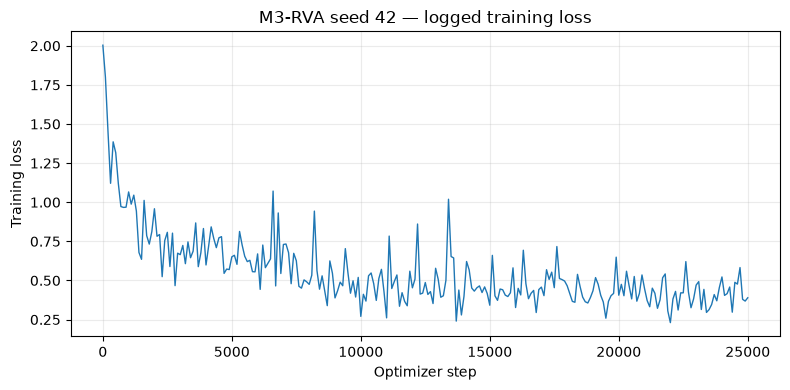

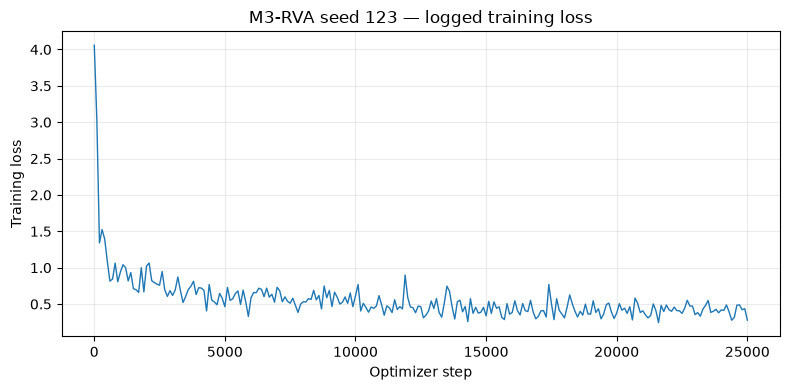

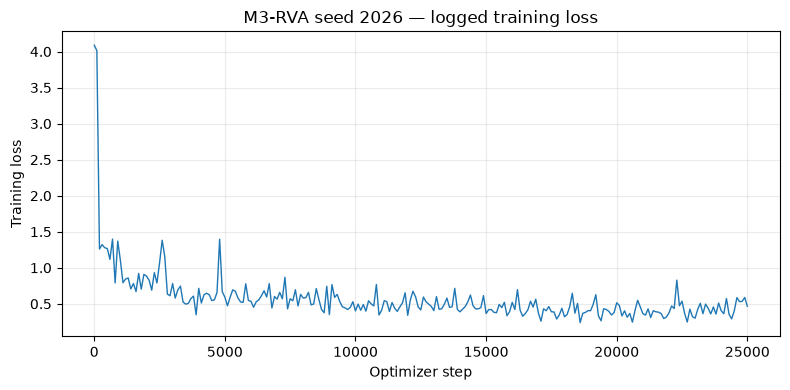

M3-RVA TRAINING STATUS: ALL_THREE_SEEDS_COMPLETE
PLANNED SEEDS: [42, 123, 2026]
COMPLETED SEEDS: [42, 123, 2026]
ROBOT SUCCESS / ROBUSTNESS: NOT_EVALUATED
CONSISTENCY ARM STARTED: NO
ORIGINAL MODELS RETRAINED: NO
SUMMARY: /home/leeming/projects/deep-learning-vla-robustness/results/metrics/m3_rva_extension/v1/training_summary.json


In [17]:
M3_SUMMARY_PATH = M3_METRICS / 'training_summary.json'
if RUN_M3_REAL_TRAINING:
    M3_TRAINING_SUMMARY = json.loads(M3_SUMMARY_PATH.read_text())
    records = M3_TRAINING_SUMMARY['results']
    display(pd.DataFrame([{
        'variant': r['variant'], 'seed': r['seed'], 'steps': r['steps'],
        'training_minutes_excluding_checkpoint_io': r['training_minutes'],
        'offline_validation_loss': r['validation_loss'],
        'peak_allocated_GiB': r['peak_allocated_gib'],
        'full_reload': r['restoration']['status'], 'checkpoint': r['checkpoint'],
    } for r in records]))
    import matplotlib.pyplot as plt
    for r in records:
        metrics_file = (M3_ROOT / r['checkpoint']).parent / 'train_metrics.csv'
        frame = pd.read_csv(metrics_file)
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(frame['step'], frame['loss'], linewidth=1)
        ax.set(title=f"M3-RVA seed {r['seed']} — logged training loss", xlabel='Optimizer step', ylabel='Training loss')
        ax.grid(True, alpha=0.25)
        fig.tight_layout()
        figure_dir = M3_ROOT / 'results/figures/m3_rva_extension'
        figure_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_dir / f"m3rva_seed{r['seed']}_training_loss.png", dpi=160)
        plt.show()
        plt.close(fig)
    print('='*76)
    print('M3-RVA TRAINING STATUS:', M3_TRAINING_SUMMARY['training_status'])
    print('PLANNED SEEDS:', M3_TRAINING_SUMMARY['planned_seeds'])
    print('COMPLETED SEEDS:', M3_TRAINING_SUMMARY['completed_seeds'])
    print('ROBOT SUCCESS / ROBUSTNESS: NOT_EVALUATED')
    print('CONSISTENCY ARM STARTED: NO')
    print('ORIGINAL MODELS RETRAINED: NO')
    print('SUMMARY:', M3_SUMMARY_PATH)
    print('='*76)
else:
    print('N09 Stage B complete. Stage C not launched. Robot success remains NOT_EVALUATED.')


## 18. Sources and implementation boundaries

The model and its original learning formulation remain **SmolVLA / Hugging Face LeRobot** work. The token-wise residual adapter is a proposed, attributed adaptation, not a claim that adapters are newly invented.

**Local primary sources used to prepare this continuation:** the uploaded, executed `06_validated_final_retraining(1).ipynb`, executed `09_custom_robust_visual_adapter(1).ipynb`, and `smolvla_source_audit.txt` at the pinned LeRobot commit. N06's batch conversion, episode-language mapping, transformations, optimizer hyperparameters, scope and schedule were retained. New contributions here are the M3 integration, deterministic recovery, explicit full checkpoint loader, and measured real-data qualification. No old notebook is executed indirectly by the runner.

**Implementation documentation:** PyTorch's [checkpointing guide](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html) describes saving optimizer state for recovery. Its [state-dictionary loading recipe](https://docs.pytorch.org/tutorials/recipes/recipes/module_load_state_dict_tips.html) explains dtype-preserving assignment and why optimizers must be created after `assign=True` loading. Those documentation pages are explanatory references, not an instruction to upgrade the pinned environment.

**Validation limitation:** generated code and isolated CPU tests do not establish compatibility with every installed GPU/library configuration. The real-data/fresh-process checks above are required and stop on failure. Report technical failures honestly; do not bypass them to obtain a PASS. Preserve the original numerical results and classify all new performance comparisons as post-hoc/exploratory. A completed training job is not a positive research finding.
